# 🎓 Encontro 2 — Processamento de Imagens e Filtros

## Operações Ponto a Ponto, Convolução e o Caminho até o Detector de Bordas

O objetivo desta aula é **entender a matemática** que define os filtros de imagem
clássicos, ao ponto de conseguirmos implementá-los nós mesmos, do zero, usando
apenas operações matriciais.

Tudo o que fizermos aqui será implementado usando **exclusivamente**:
- `numpy` → para toda a matemática e manipulação matricial;
- `matplotlib` → para leitura e exibição de imagens.

**Não vamos usar `cv2`, `PIL`/`Pillow`, `skimage` ou qualquer outra biblioteca de visão computacional de alto nível.** Se uma operação existe "pronta" nessas bibliotecas — incluindo `Otsu`, `Non-Maximum Suppression` ou até a própria convolução — nós vamos recriá-la manualmente com NumPy, com a matemática completa por trás.

In [ ]:
%pip install matplotlib numpy

In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view

### Roteiro da aula
0. Configuração do ambiente de desenvolvimento
1. Fundamentos matemáticos das imagens digitais
2. Operações ponto a ponto: Brilho/Contraste, Canal Alpha, Saturação/Matiz (HSV)
3. Convolução: definição formal, padding, implementação ingênua vs. vetorizada
   (im2col), separabilidade de kernels e convolução no domínio da frequência (FFT)
4. Filtros clássicos: Blur, Sharpen e Sobel
5. Do gradiente ao mapa binário de bordas: Supressão de Não-Máximos (NMS) e
   limiarização automática (método de Otsu)
6. Pipeline completo de detecção de bordas (um "quase-Canny")
7. Testes e leitura crítica

---


## 0. Configuração do ambiente de desenvolvimento

Instalando a IDE https://code.visualstudio.com/

Instalando o Python (uv) https://docs.astral.sh/uv/getting-started/installation/
- uv install 3.12
- uv init
- uv venv
- uv add


## 1. Fundamentos Matemáticos das Imagens Digitais

Do ponto de vista matemático, uma imagem digital é uma **função discretizada**
$f(x,y)$ que mapeia uma posição espacial $(x,y)$ a uma intensidade de cor. Como
um computador não armazena funções contínuas, nós a **amostramos** em uma grade
regular de pontos — a **matriz de pixels**.

**Imagem em tons de cinza:** uma matriz 2D, $I \in \mathbb{Z}^{H \times W}$, com
$I(y, x) \in [0, 255]$, onde $H$ é a altura e $W$ é a largura em pixels.

**Imagem colorida (RGB):** um tensor 3D, $I \in \mathbb{Z}^{H \times W \times 3}$,
com $I(y, x, c) \in [0, 255]$, onde $c \in \{0,1,2\}$ indexa os canais Vermelho,
Verde e Azul. Cada pixel é uma tripla $(R, G, B)$.

### ⚠️ Convenção de indexação: (linha, coluna) ≠ (x, y)

Em NumPy/álgebra matricial indexamos por **(linha, coluna)**, ou seja
`imagem[y, x]`, e **não** `imagem[x, y]`. O eixo 0 percorre a altura (vertical);
o eixo 1 percorre a largura (horizontal). Confundir essa convenção é uma das
fontes de erro mais comuns em Visão Computacional.

### Faixa de valores: `uint8` (0–255) vs. `float` (0–1)

Cada canal costuma ser armazenado como inteiro sem sinal de 8 bits (`uint8`),
permitindo $2^8 = 256$ níveis. Ótimo para armazenamento, mas traiçoeiro para
**cálculo aritmético** — como veremos a seguir. A regra prática: sempre
converter para `float64` antes de somar/multiplicar, e só "saturar" (clip) de
volta para $[0, 255]$ no final, ao exibir ou salvar.


In [3]:
a = np.array([200], dtype=np.uint8)
b = np.array([100], dtype=np.uint8)

print("200 + 100 direto em uint8 (SEM cuidado):", a + b, " <- errado! (overflow, mod 256)")
print("200 + 100 em float64 (COM cuidado):     ", a.astype(np.float64) + b.astype(np.float64))


def garantir_uint8(imagem):
    '''
    Satura (clipa) os valores no intervalo [0, 255] e converte para uint8.

    É a "porta de saída" de toda operação ponto a ponto ou filtro espacial
    desta aula: fazemos a matemática em float64 e só chamamos garantir_uint8()
    antes de exibir ou salvar o resultado.
    '''
    return np.clip(imagem, 0, 255).astype(np.uint8)

200 + 100 direto em uint8 (SEM cuidado): [44]  <- errado! (overflow, mod 256)
200 + 100 em float64 (COM cuidado):      [300.]


Shape da imagem (H, W, C): (825, 1100, 3)
Tipo de dado (dtype):      uint8
Valor mínimo de pixel:     0
Valor máximo de pixel:     255

Exemplo — pixel na posição (y=100, x=150): [ 8 26 12] -> (R, G, B)


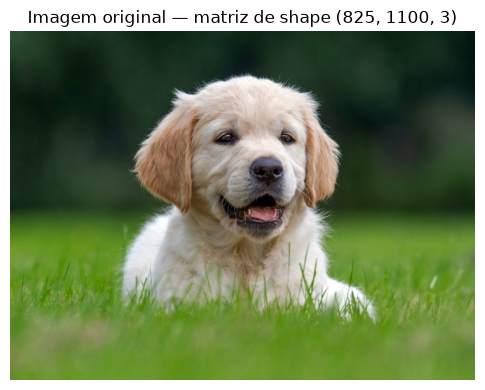

In [4]:
def reduzir_imagem(imagem, fator):
    '''
    Reduz a imagem por decimação simples (pega 1 a cada `fator` pixels em cada
    eixo). Não é uma técnica de resize de alta qualidade (não há
    anti-aliasing), mas é suficiente (e 100% NumPy) para deixar nossos
    experimentos de convolução rápidos.
    '''
    return imagem[::fator, ::fator, ...]


caminho_imagem = './imgs/dog.jpg'
imagem_original = plt.imread(caminho_imagem)

print("Shape da imagem (H, W, C):", imagem_original.shape)
print("Tipo de dado (dtype):     ", imagem_original.dtype)
print("Valor mínimo de pixel:    ", imagem_original.min())
print("Valor máximo de pixel:    ", imagem_original.max())

y, x = 100, 150
print(f"\nExemplo — pixel na posição (y={y}, x={x}):", imagem_original[y, x], "-> (R, G, B)")

plt.figure(figsize=(6, 6))
plt.imshow(imagem_original)
plt.title(f"Imagem original — matriz de shape {imagem_original.shape}")
plt.axis('off')
plt.show()

Podemos visualizar cada canal de cor separadamente, "fatiando" a última
dimensão do tensor. `imagem[:, :, 0]` nos dá **apenas** a matriz 2D com as
intensidades de vermelho — perdemos a informação de cor, mas ganhamos a
possibilidade de tratar cada canal como uma imagem em tons de cinza
independente.


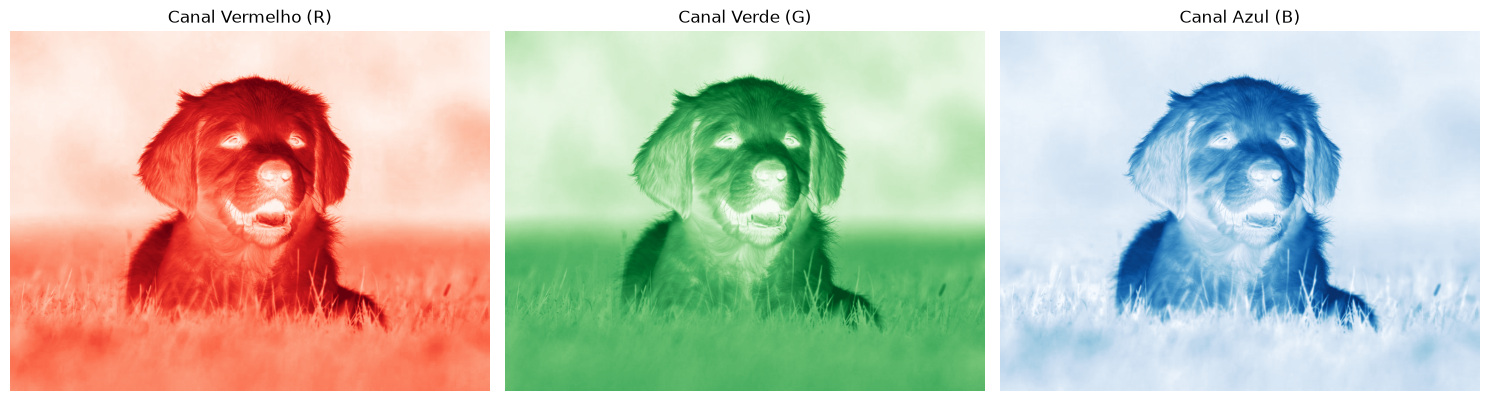

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
nomes_canais = ['Canal Vermelho (R)', 'Canal Verde (G)', 'Canal Azul (B)']
mapas_de_cor = ['Reds', 'Greens', 'Blues']

for i in range(3):
    axs[i].imshow(imagem_original[:, :, i], cmap=mapas_de_cor[i])
    axs[i].set_title(nomes_canais[i])
    axs[i].axis('off')

plt.tight_layout()
plt.show()

## 2. Operações Ponto a Ponto (Ajustes de Cor e Luz)

Uma **operação ponto a ponto** (*point operation* / *transformação de
intensidade*) é qualquer transformação em que o valor de saída de um pixel
depende **apenas** do valor de entrada daquele mesmo pixel — nunca de seus
vizinhos:

$$ g(x,y) = T\big(f(x,y)\big) $$

Isso é bem diferente dos **filtros espaciais** que veremos na Seção 3, onde o
valor de saída depende de uma vizinhança de pixels. Brilho, contraste,
transparência e ajustes de cor (HSV) são exemplos de operações ponto a ponto.

### 2.1 Brilho e Contraste

A transformação linear mais simples (e mais usada) é:

$$ g(x,y) = \alpha \cdot f(x,y) + \beta $$

- $\alpha$ (**ganho**) controla o **contraste**: $\alpha > 1$ afasta as
  intensidades da média (mais contraste); $0 < \alpha < 1$ as aproxima (menos
  contraste).
- $\beta$ (**offset**) controla o **brilho**: soma (ou subtrai) uma quantidade
  fixa de intensidade a todos os pixels.

Geometricamente, $\alpha$ é a inclinação de uma reta e $\beta$ o ponto onde ela
cruza o eixo Y — é a transformação linear $y = \alpha x + \beta$ aplicada à
intensidade de cada pixel.

Como o resultado facilmente sai de $[0, 255]$ (ex.: $250 \times 1.5 = 375$), é
essencial **saturar** (clip) o resultado — o mesmo fenômeno de *clipping* que
ocorre em sensores de câmera reais, "estourando" regiões muito claras para
branco puro e afundando regiões muito escuras para preto puro.


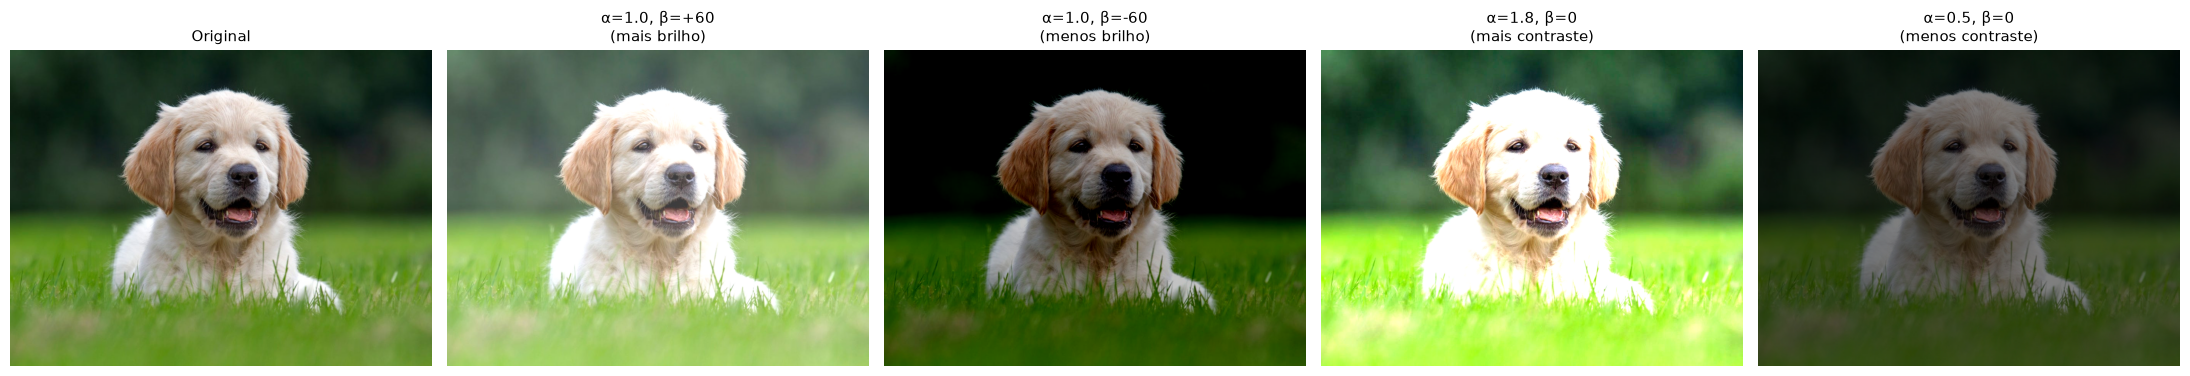

In [6]:
def ajustar_brilho_contraste(imagem, alpha=1.0, beta=0):
    '''
    Aplica g(x,y) = alpha * f(x,y) + beta, pixel a pixel.

    alpha : ganho de contraste (1.0 = neutro; >1 aumenta, <1 diminui)
    beta  : deslocamento de brilho (0 = neutro; soma/subtrai intensidade)
    '''
    imagem_float = imagem.astype(np.float64)
    saida = alpha * imagem_float + beta
    return garantir_uint8(saida)


mais_brilho = ajustar_brilho_contraste(imagem_original, alpha=1.0, beta=60)
menos_brilho = ajustar_brilho_contraste(imagem_original, alpha=1.0, beta=-60)
mais_contraste = ajustar_brilho_contraste(imagem_original, alpha=1.8, beta=0)
menos_contraste = ajustar_brilho_contraste(imagem_original, alpha=0.5, beta=0)

imagens = [imagem_original, mais_brilho, menos_brilho, mais_contraste, menos_contraste]
titulos = ['Original', 'α=1.0, β=+60\n(mais brilho)', 'α=1.0, β=-60\n(menos brilho)',
           'α=1.8, β=0\n(mais contraste)', 'α=0.5, β=0\n(menos contraste)']

fig, axs = plt.subplots(1, 5, figsize=(22, 5))
for ax, im, t in zip(axs, imagens, titulos):
    ax.imshow(im)
    ax.set_title(t, fontsize=11)
    ax.axis('off')
plt.tight_layout()
plt.show()

### 2.2 Canal Alpha (Transparência)

O canal **alpha** ($\alpha$, não confundir com o $\alpha$ de contraste acima —
notação infelizmente reaproveitada na literatura) adiciona uma **quarta
dimensão** à imagem: de RGB ($H \times W \times 3$) para **RGBA**
($H \times W \times 4$). Ele não representa cor, e sim um **peso de
opacidade** por pixel: $0$ = totalmente transparente, $255$ (ou $1.0$
normalizado) = totalmente opaco.

O canal alpha, isoladamente, não produz efeito visual — ele só *carrega*
opacidade. O efeito aparece na **composição alfa** (*alpha compositing*, o
operador `over`) de uma imagem de frente sobre um fundo:

$$ C_{\text{final}} = \alpha \cdot C_{\text{frente}} + (1-\alpha) \cdot C_{\text{fundo}} $$

Essa é uma interpolação linear (`lerp`) entre a cor de frente e a cor de
fundo, ponderada pelo alpha, aplicada por canal e por pixel.

> 💡 `plt.imread()` retorna 4 canais (RGBA) para PNG, mas apenas 3 (RGB) para
> JPEG — JPEG não suporta transparência. Por isso, na nossa imagem `.jpeg`,
> vamos **adicionar** o canal alpha manualmente.


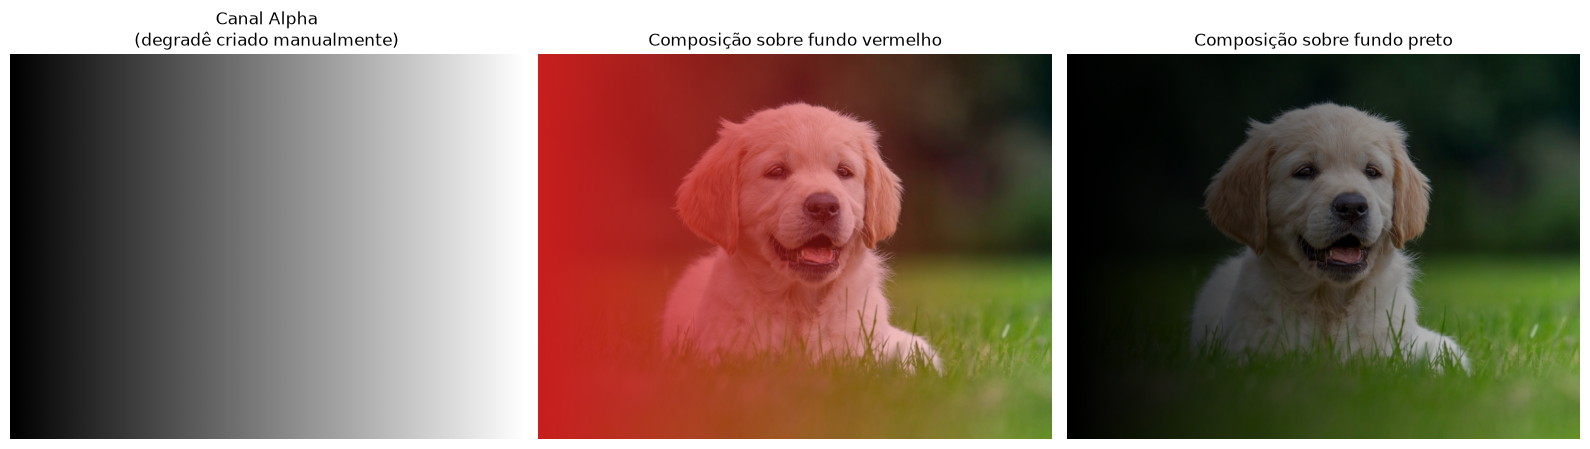

In [7]:
def adicionar_canal_alpha(imagem, valor_alpha=255):
    '''Adiciona um 4º canal (transparência) a uma imagem RGB, gerando RGBA.'''
    H, W, _ = imagem.shape
    canal_alpha = np.full((H, W, 1), valor_alpha, dtype=np.uint8)
    return np.concatenate([imagem, canal_alpha], axis=2)


def aplicar_transparencia(imagem_rgba, cor_fundo=(255, 255, 255)):
    '''Composição alfa ("over operator") de uma RGBA sobre um fundo sólido -> RGB.'''
    frente = imagem_rgba[..., :3].astype(np.float64)
    alpha = imagem_rgba[..., 3:4].astype(np.float64) / 255.0
    fundo = np.array(cor_fundo, dtype=np.float64)

    saida = alpha * frente + (1 - alpha) * fundo
    return garantir_uint8(saida)


imagem_rgba = adicionar_canal_alpha(imagem_original, valor_alpha=255)

# degradê de transparência apenas para visualizarmos o efeito da composição
H, W, _ = imagem_original.shape
degrade = np.linspace(0, 255, W)
imagem_rgba[..., 3] = np.tile(degrade, (H, 1)).astype(np.uint8)

fundo_vermelho = aplicar_transparencia(imagem_rgba, cor_fundo=(200, 30, 30))
fundo_preto = aplicar_transparencia(imagem_rgba, cor_fundo=(0, 0, 0))

fig, axs = plt.subplots(1, 3, figsize=(16, 5))
axs[0].imshow(imagem_rgba[..., 3], cmap='gray')
axs[0].set_title('Canal Alpha\n(degradê criado manualmente)')
axs[1].imshow(fundo_vermelho)
axs[1].set_title('Composição sobre fundo vermelho')
axs[2].imshow(fundo_preto)
axs[2].set_title('Composição sobre fundo preto')
for ax in axs:
    ax.axis('off')
plt.tight_layout()
plt.show()

### 2.3 Saturação e Matiz (Hue) — o espaço de cor HSV

O espaço **RGB** é ótimo para displays, mas péssimo para *editar* cor: brilho
e cor estão misturados em três canais fortemente correlacionados — não existe
um canal isolado de "saturação" ou "matiz".

O espaço **HSV** (*Hue, Saturation, Value*) separa essa informação em três
eixos organizados como um cilindro:

- **H (Matiz)**: ângulo de $0°$ a $360°$ na roda de cores (0°=vermelho,
  120°=verde, 240°=azul).
- **S (Saturação)**: de $0$ (cinza) a $1$ (cor pura) — distância até o eixo
  neutro do cilindro.
- **V (Valor/Brilho)**: de $0$ (preto) a $1$ (mais claro) — altura no cilindro.

#### Conversão RGB → HSV

Com $R, G, B \in [0, 1]$:

$$ C_{max} = \max(R,G,B), \qquad C_{min} = \min(R,G,B), \qquad \Delta = C_{max} - C_{min} $$

$$
H =
\begin{cases}
0° & \text{se } \Delta = 0 \\[4pt]
60° \times \left(\dfrac{G-B}{\Delta} \bmod 6\right) & \text{se } C_{max} = R \\[8pt]
60° \times \left(\dfrac{B-R}{\Delta} + 2\right) & \text{se } C_{max} = G \\[8pt]
60° \times \left(\dfrac{R-G}{\Delta} + 4\right) & \text{se } C_{max} = B
\end{cases}
$$

$$
S = \begin{cases} 0 & \text{se } C_{max} = 0 \\ \Delta / C_{max} & \text{caso contrário} \end{cases}
\qquad\qquad
V = C_{max}
$$

#### Conversão HSV → RGB (o caminho de volta)

$$ C = V \cdot S, \qquad X = C \cdot \left(1 - \left|\left(\dfrac{H}{60°} \bmod 2\right) - 1\right|\right), \qquad m = V - C $$

Dependendo do "setor" de 60° em que $H$ cai, $(R', G', B')$ assume um entre 6
padrões envolvendo $C$, $X$ e $0$ — e a cor final é $(R'+m,\ G'+m,\ B'+m)$.

**Implementação sem loops:** cada `if/else` acima vira uma **máscara
booleana** do NumPy (`array == condição`), aplicada sobre a imagem inteira de
uma só vez — assim "percorremos a matriz" eficientemente, sem loop Python
pixel a pixel.


In [8]:
def rgb_para_hsv(imagem):
    '''
    Converte uma imagem RGB (uint8, 0-255) para HSV.
    H fica em graus [0, 360), S e V normalizados em [0, 1].
    Totalmente vetorizado: nenhum loop Python percorre os pixels.
    '''
    img = imagem.astype(np.float64) / 255.0
    R, G, B = img[..., 0], img[..., 1], img[..., 2]

    Cmax = np.max(img, axis=-1)
    Cmin = np.min(img, axis=-1)
    Delta = Cmax - Cmin

    H = np.zeros_like(Cmax)
    tem_cor = Delta != 0

    idx = tem_cor & (Cmax == R)
    H[idx] = 60 * (((G[idx] - B[idx]) / Delta[idx]) % 6)

    idx = tem_cor & (Cmax == G) & (Cmax != R)
    H[idx] = 60 * (((B[idx] - R[idx]) / Delta[idx]) + 2)

    idx = tem_cor & (Cmax == B) & (Cmax != R) & (Cmax != G)
    H[idx] = 60 * (((R[idx] - G[idx]) / Delta[idx]) + 4)

    S = np.zeros_like(Cmax)
    nao_e_preto = Cmax != 0
    S[nao_e_preto] = Delta[nao_e_preto] / Cmax[nao_e_preto]

    V = Cmax
    return np.stack([H, S, V], axis=-1)


def hsv_para_rgb(imagem_hsv):
    '''Converte HSV (H em graus, S e V em [0,1]) de volta para RGB uint8.'''
    H, S, V = imagem_hsv[..., 0], imagem_hsv[..., 1], imagem_hsv[..., 2]

    C = V * S
    Hp = H / 60.0
    X = C * (1 - np.abs((Hp % 2) - 1))
    m = V - C

    Rp = np.zeros_like(H)
    Gp = np.zeros_like(H)
    Bp = np.zeros_like(H)

    setor = [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 6)]
    valores = [(C, X, 0), (X, C, 0), (0, C, X), (0, X, C), (X, 0, C), (C, 0, X)]

    for (ini, fim), (r, g, b) in zip(setor, valores):
        idx = (Hp >= ini) & (Hp < fim)
        Rp[idx] = r[idx] if hasattr(r, '__getitem__') else r
        Gp[idx] = g[idx] if hasattr(g, '__getitem__') else g
        Bp[idx] = b[idx] if hasattr(b, '__getitem__') else b

    rgb = np.stack([Rp + m, Gp + m, Bp + m], axis=-1) * 255.0
    return garantir_uint8(rgb)

In [9]:
# Sanity check: RGB -> HSV -> RGB deve recuperar (quase) exatamente a imagem
# original (pequenas diferenças vêm de arredondamento em ponto flutuante).
hsv_teste = rgb_para_hsv(imagem_original)
volta_para_rgb = hsv_para_rgb(hsv_teste)

diferenca = np.abs(imagem_original.astype(np.float64) - volta_para_rgb.astype(np.float64))
print("Diferença máxima após ida e volta RGB->HSV->RGB:", diferenca.max())
print("Diferença média após ida e volta RGB->HSV->RGB: ", round(diferenca.mean(), 4))
assert diferenca.max() <= 2, "Round-trip RGB<->HSV com erro inesperadamente alto"

Diferença máxima após ida e volta RGB->HSV->RGB: 1.0
Diferença média após ida e volta RGB->HSV->RGB:  0.0911


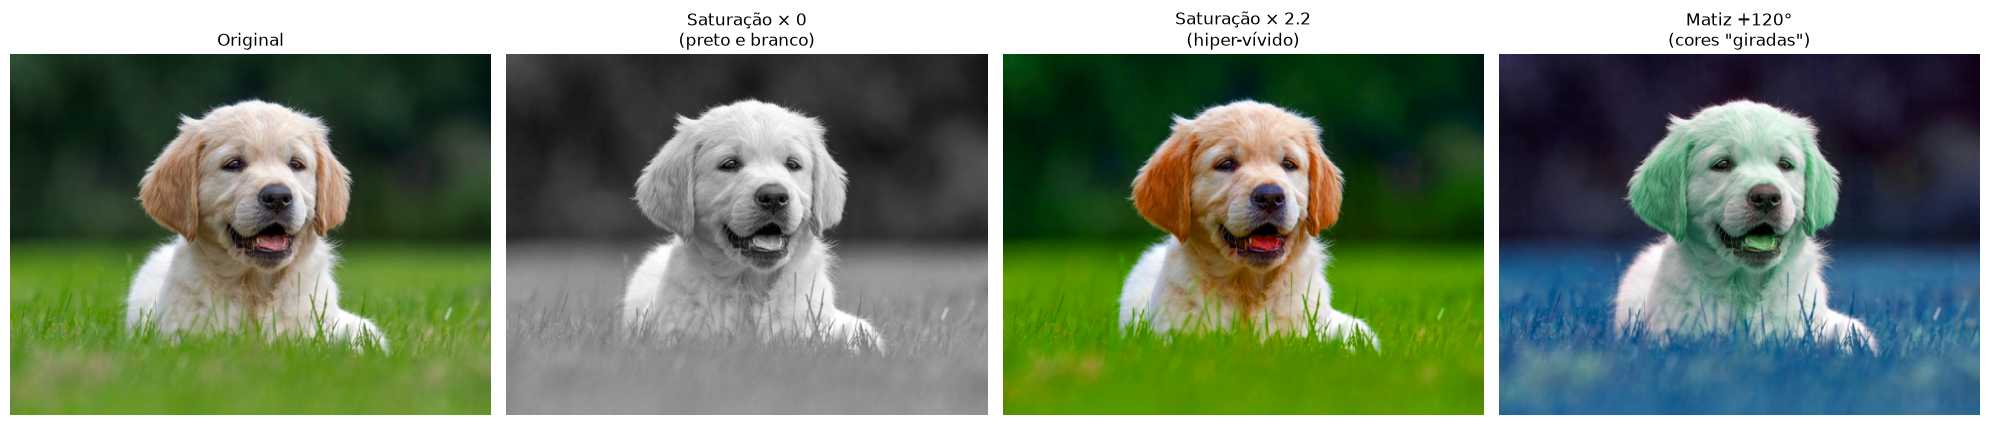

In [10]:
def ajustar_saturacao_matiz(imagem, fator_saturacao=1.0, deslocamento_matiz=0.0):
    '''
    fator_saturacao    : multiplica o canal S (0 = P&B, 1 = neutro, >1 = mais vívido)
    deslocamento_matiz : soma, em graus, ao canal H — "gira" as cores na roda de cores
    '''
    hsv = rgb_para_hsv(imagem)
    H, S, V = hsv[..., 0], hsv[..., 1], hsv[..., 2]

    H_novo = (H + deslocamento_matiz) % 360
    S_novo = np.clip(S * fator_saturacao, 0, 1)

    hsv_novo = np.stack([H_novo, S_novo, V], axis=-1)
    return hsv_para_rgb(hsv_novo)


dessaturada = ajustar_saturacao_matiz(imagem_original, fator_saturacao=0.0)
supersaturada = ajustar_saturacao_matiz(imagem_original, fator_saturacao=2.2)
matiz_deslocada = ajustar_saturacao_matiz(imagem_original, deslocamento_matiz=120)

fig, axs = plt.subplots(1, 4, figsize=(20, 5))
imagens = [imagem_original, dessaturada, supersaturada, matiz_deslocada]
titulos = ['Original', 'Saturação × 0\n(preto e branco)', 'Saturação × 2.2\n(hiper-vívido)',
           'Matiz +120°\n(cores "giradas")']
for ax, im, t in zip(axs, imagens, titulos):
    ax.imshow(im)
    ax.set_title(t)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 3. Convolução: Teoria e Implementações

Diferente das operações ponto a ponto, um **filtro espacial** calcula cada
pixel de saída a partir de uma **vizinhança** de pixels de entrada. É assim
que blur, sharpen e Sobel funcionam.

### 3.1 Kernel e convolução discreta

Um **kernel** (ou máscara) é uma pequena matriz de pesos (tipicamente
$3\times3$, $5\times5$, sempre de dimensão ímpar) que "deslizamos" sobre cada
posição da imagem, multiplicando e somando.

A **convolução 2D discreta** entre uma imagem $f$ e um kernel $h$ de tamanho
$(2a+1) \times (2b+1)$ é:

$$ (f * h)(x,y) = \sum_{i=-a}^{a} \sum_{j=-b}^{b} f(x-i,\, y-j)\, h(i,j) $$

O sinal negativo em $f(x-i, y-j)$ indica que a convolução **inverte o kernel
em 180°** antes de deslizá-lo. Se não invertêssemos, a operação seria a
**correlação cruzada** — que é, na prática, o que a maioria das bibliotecas
chama informalmente de "convolução". Para kernels simétricos (blur), tanto
faz; para kernels assimétricos (Sobel), a diferença de sinal existe, mas
desaparece ao elevarmos ao quadrado (Seção 4.3).

Essa distinção importa porque a **convolução verdadeira** é a operação que
satisfaz as propriedades algébricas exploradas mais adiante nesta seção:

$$
\underbrace{f * h = h * f}_{\text{comutatividade}}
\qquad\qquad
\underbrace{f * (h_1 + h_2) = f*h_1 + f*h_2}_{\text{linearidade}}
\qquad\qquad
\underbrace{f * (h_1 * h_2) = (f * h_1) * h_2}_{\text{associatividade}}
$$

A associatividade é o que garante, por exemplo, que aplicar dois blurs em
sequência equivale a aplicar um único blur com um kernel maior (a convolução
dos dois kernels) — e é a propriedade que sustenta a **separabilidade de
kernels** (Seção 3.5) e o **Teorema da Convolução** (Seção 3.6).

### O problema da borda

Se o kernel tem tamanho $k \times k$, calcular a saída nos pixels próximos à
borda exige $\lfloor k/2 \rfloor$ vizinhos que **não existem**. Isso é
resolvido com **padding** — preenchimento artificial das bordas, discutido a
seguir.


### 3.2 Padding (Preenchimento): as três estratégias clássicas

- **Zero-padding** (`constant`): preenche com zeros. Simples, mas cria uma
  **moldura escura artificial** depois de um blur — o filtro passa a incluir
  "preto" na média de pixels próximos à borda, escurecendo-os.
- **Replicação** (`edge`): repete o valor do pixel da borda. Evita a moldura
  escura, mas pode gerar pequenas listras (o valor repetido "empasta" na
  direção perpendicular à borda).
- **Reflexão** (`reflect`): espelha a imagem como se houvesse um espelho na
  borda. Preserva melhor a estatística local de intensidade, mas introduz uma
  **descontinuidade na derivada** exatamente na borda (o "espelho" cria um
  vinco), o que pode gerar artefatos em filtros derivativos como o Sobel.

Não existe padding "certo" universalmente — a escolha depende do filtro e do
que se quer preservar. Nesta aula usaremos principalmente **replicação**
(bom compromisso para blur/sharpen/Sobel), mas vamos comparar as três
visualmente para deixar o trade-off explícito.


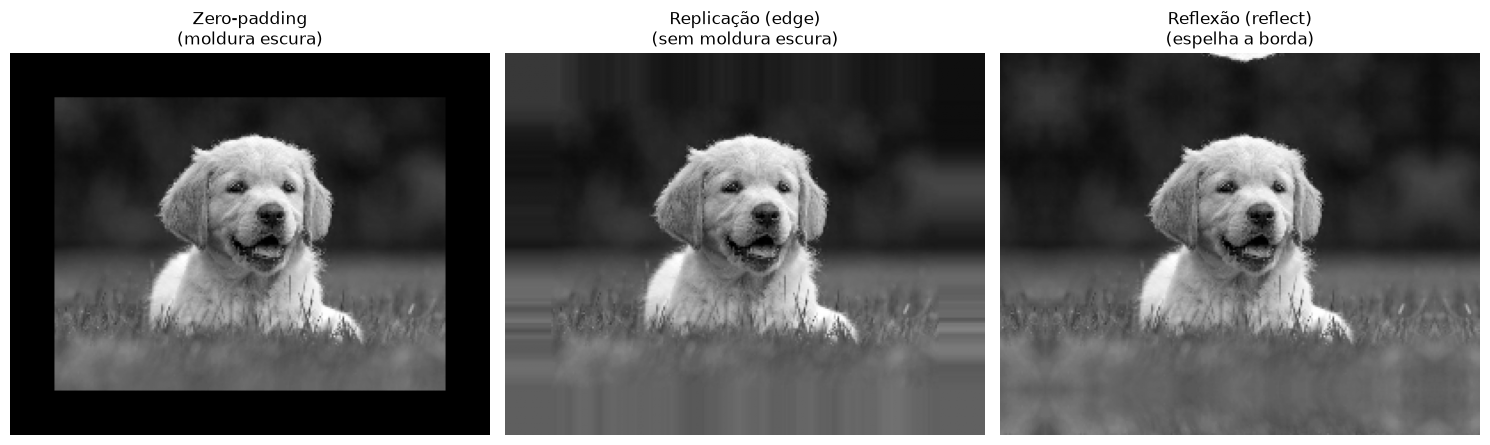

In [11]:
def aplicar_padding(canal, pad_h, pad_w, modo='edge'):
    '''Encapsula np.pad para um único canal HxW, com os 3 modos discutidos.'''
    modos_validos = {'constant', 'edge', 'reflect'}
    if modo not in modos_validos:
        raise ValueError(f"modo deve ser um de {modos_validos}")
    return np.pad(canal, ((pad_h, pad_h), (pad_w, pad_w)), mode=modo)


imagem_demo = reduzir_imagem(imagem_original, 5)
canal_cinza_demo = imagem_demo.astype(np.float64).mean(axis=2)

pad = 25  # exagerado de propósito, só para deixar o efeito visível
zero_pad = aplicar_padding(canal_cinza_demo, pad, pad, modo='constant')
edge_pad = aplicar_padding(canal_cinza_demo, pad, pad, modo='edge')
reflect_pad = aplicar_padding(canal_cinza_demo, pad, pad, modo='reflect')

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, im, t in zip(axs, [zero_pad, edge_pad, reflect_pad],
                      ['Zero-padding\n(moldura escura)', 'Replicação (edge)\n(sem moldura escura)',
                       'Reflexão (reflect)\n(espelha a borda)']):
    ax.imshow(im, cmap='gray')
    ax.set_title(t)
    ax.axis('off')
plt.tight_layout()
plt.show()

### 3.3 Implementação ingênua (laços explícitos)

A implementação abaixo usa dois laços `for` para deixar a matemática
**absolutamente explícita** — a fórmula da convolução vira código, pixel a
pixel. É lenta (Python puro), mas serve de referência de correção para as
versões vetorizadas que virão a seguir.


In [12]:
def _convolucao_2d_loop(canal, kernel, modo_padding='edge'):
    '''
    Convolução 2D discreta de um único canal (matriz HxW), literalmente:
        saida[y, x] = soma_i soma_j  canal_com_borda[y+i, x+j] * kernel_invertido[i, j]
    '''
    kernel_invertido = kernel[::-1, ::-1]          # <- é isso que torna a operação uma convolução de verdade
    kh, kw = kernel_invertido.shape
    ph, pw = kh // 2, kw // 2

    canal_com_borda = aplicar_padding(canal, ph, pw, modo=modo_padding)

    H, W = canal.shape
    saida = np.zeros((H, W), dtype=np.float64)

    for y in range(H): # Para cada y em Height (Altura)
        for x in range(W): # Para cada x em Width (Largura)
            regiao = canal_com_borda[y:y + kh, x:x + kw]
            saida[y, x] = np.sum(regiao * kernel_invertido)

    return saida


def aplicar_convolucao(imagem, kernel, modo_padding='edge'):
    '''
    Convolução 2D genérica: funciona para imagens em tons de cinza (HxW) e
    coloridas (HxWxC) — cada canal é convoluído de forma independente.
    '''
    kernel = np.asarray(kernel, dtype=np.float64)

    if imagem.ndim == 2:
        return _convolucao_2d_loop(imagem.astype(np.float64), kernel, modo_padding)

    canais_filtrados = [
        _convolucao_2d_loop(imagem[..., c].astype(np.float64), kernel, modo_padding)
        for c in range(imagem.shape[-1])
    ]
    return np.stack(canais_filtrados, axis=-1)

In [13]:
# Sanity check: um kernel "identidade" (1 no centro, 0 no resto) não deve
# alterar a imagem em nada — equivalente à multiplicação por 1.
kernel_identidade = np.array([
    [0, 0, 0],
    [0, 1, 0],
    [0, 0, 0],
], dtype=np.float64)

matriz_teste = np.arange(25).reshape(5, 5).astype(np.float64)
resultado_teste = aplicar_convolucao(matriz_teste, kernel_identidade)

print("Matriz de teste:\n", matriz_teste)
print("\nO kernel identidade preserva a imagem?", np.allclose(matriz_teste, resultado_teste))
assert np.allclose(matriz_teste, resultado_teste)

Matriz de teste:
 [[ 0.  1.  2.  3.  4.]
 [ 5.  6.  7.  8.  9.]
 [10. 11. 12. 13. 14.]
 [15. 16. 17. 18. 19.]
 [20. 21. 22. 23. 24.]]

O kernel identidade preserva a imagem? True


### 3.4 Vetorização via Im2Col

O maior custo da implementação ingênua é o **laço Python** — cada iteração do
`for` tem overhead de interpretador, e não aproveita BLAS/SIMD. A técnica
**Im2Col** ("*image to column*"), usada internamente por frameworks de deep
learning para implementar convolução como GEMM (multiplicação de matrizes),
resolve isso assim:

1. Para cada posição $(y,x)$ da imagem, extraímos a vizinhança $k \times k$
   correspondente e a "achatamos" em um vetor de tamanho $k^2$.
2. Empilhamos todos esses vetores como **linhas** de uma matriz gigante
   $\text{Col} \in \mathbb{R}^{(HW) \times k^2}$.
3. Achatamos o kernel invertido em um vetor coluna $\vec{h} \in \mathbb{R}^{k^2}$.
4. A convolução inteira vira **uma única multiplicação matriz-vetor**:

$$ \vec{g} = \text{Col} \cdot \vec{h} \qquad\qquad g[y,x] = \vec{g}\big[y \cdot W + x\big] $$

O NumPy nos dá `sliding_window_view`, que gera essas janelas **sem copiar
dados** (usa *strides* de memória) — o `reshape` final é que materializa a
matriz `Col`. Trocamos $H \times W$ iterações Python por uma única chamada a
uma rotina de multiplicação de matrizes altamente otimizada (BLAS).

**Complexidade:** ambas as versões são $O(H \cdot W \cdot k^2)$ em número de
multiplicações — a vetorização não muda a ordem de grandeza do trabalho
aritmético, mas elimina o overhead do interpretador Python por operação, que
domina o tempo total quando $k$ é pequeno.


In [14]:
def _convolucao_2d_im2col(canal, kernel, modo_padding='edge'):
    '''Mesma convolução de _convolucao_2d_loop, mas via Im2Col + GEMM (sem laços sobre pixels).'''
    kernel_invertido = kernel[::-1, ::-1]
    kh, kw = kernel_invertido.shape
    ph, pw = kh // 2, kw // 2

    canal_com_borda = aplicar_padding(canal, ph, pw, modo=modo_padding)
    H, W = canal.shape

    # janelas: shape (H, W, kh, kw), sem copiar dados (usa strides, que são apenas "saltos" na memória)
    janelas = sliding_window_view(canal_com_borda, (kh, kw))

    col = janelas.reshape(H * W, kh * kw)          # "Col": cada linha = uma vizinhança achatada
    h_vetor = kernel_invertido.reshape(kh * kw, 1)  # kernel achatado em coluna

    saida = col @ h_vetor                          # convolução inteira = 1 multiplicação de matrizes
    return saida.reshape(H, W)


def aplicar_convolucao_im2col(imagem, kernel, modo_padding='edge'):
    kernel = np.asarray(kernel, dtype=np.float64)
    if imagem.ndim == 2:
        return _convolucao_2d_im2col(imagem.astype(np.float64), kernel, modo_padding)

    canais_filtrados = [
        _convolucao_2d_im2col(imagem[..., c].astype(np.float64), kernel, modo_padding)
        for c in range(imagem.shape[-1])
    ]
    return np.stack(canais_filtrados, axis=-1)


# Benchmark: laço explícito vs. Im2Col, no mesmo kernel gaussiano 5x5
kernel_teste = np.ones((5, 5)) / 25.0

inicio = time.perf_counter()
saida_loop = aplicar_convolucao(canal_cinza_demo, kernel_teste)
tempo_loop = time.perf_counter() - inicio

inicio = time.perf_counter()
saida_im2col = aplicar_convolucao_im2col(canal_cinza_demo, kernel_teste)
tempo_im2col = time.perf_counter() - inicio

print(f"Imagem de teste: {canal_cinza_demo.shape}")
print(f"Laço explícito : {tempo_loop:.4f} s")
print(f"Im2Col (GEMM)  : {tempo_im2col:.4f} s   (speedup: {tempo_loop / tempo_im2col:.1f}x)")
print("\nResultados numericamente idênticos?", np.allclose(saida_loop, saida_im2col))
assert np.allclose(saida_loop, saida_im2col)

Imagem de teste: (165, 220)
Laço explícito : 0.1003 s
Im2Col (GEMM)  : 0.0037 s   (speedup: 27.4x)

Resultados numericamente idênticos? True


### 3.5 Separabilidade de Kernels

Um kernel 2D $h(i,j)$ é **separável** se puder ser escrito como o produto
externo de dois kernels 1D:

$$ h(i,j) = h_x(j) \cdot h_y(i) \qquad\Longleftrightarrow\qquad h = \vec{h_y}\, \vec{h_x}^{\top} $$

O kernel Gaussiano é separável porque a exponencial de uma soma é o produto
de exponenciais:

$$
G(i,j) = \frac{1}{2\pi\sigma^2} e^{-\frac{i^2+j^2}{2\sigma^2}}
       = \underbrace{\left(\frac{1}{\sqrt{2\pi}\sigma} e^{-\frac{j^2}{2\sigma^2}}\right)}_{h_x(j)}
         \cdot
         \underbrace{\left(\frac{1}{\sqrt{2\pi}\sigma} e^{-\frac{i^2}{2\sigma^2}}\right)}_{h_y(i)}
$$

**Por que isso importa?** Pela associatividade da convolução
($f * h = f * (\vec{h_y}\vec{h_x}^\top) = (f * \vec{h_x}) * \vec{h_y}$),
podemos aplicar **duas convoluções 1D** (uma por linha, outra por coluna) em
vez de uma convolução 2D completa:

- Convolução 2D direta: $O(k^2)$ multiplicações por pixel.
- Duas convoluções 1D em sequência: $O(2k)$ multiplicações por pixel.

Para $k=15$, isso é uma redução de $225 \to 30$ multiplicações por pixel — um
ganho que cresce linearmente com $k$. É por isso que implementações
profissionais de blur Gaussiano (incluindo `cv2.GaussianBlur`) sempre exploram
a separabilidade internamente.

> Nem todo kernel é separável (o Laplaciano do sharpen, por exemplo, não é) —
> mas quando é (Gaussiano, média, Sobel), vale a pena explorar.


In [15]:
def kernel_gaussiano_1d(tamanho=5, sigma=1.0):
    '''Kernel gaussiano 1D, normalizado para somar 1.'''
    eixo = np.arange(tamanho) - (tamanho - 1) / 2.0
    kernel = np.exp(-(eixo**2) / (2.0 * sigma**2))
    return kernel / kernel.sum()


def kernel_gaussiano_2d(tamanho=5, sigma=1.0):
    '''Kernel gaussiano 2D, calculado diretamente da fórmula da distribuição normal.'''
    eixo = np.arange(tamanho) - (tamanho - 1) / 2.0
    xx, yy = np.meshgrid(eixo, eixo)
    kernel = np.exp(-(xx**2 + yy**2) / (2.0 * sigma**2))
    return kernel / kernel.sum()


def convolucao_separavel(imagem, kernel_1d, modo_padding='edge'):
    '''Aplica o kernel 1D como duas convoluções (horizontal, depois vertical).'''
    horizontal = aplicar_convolucao(imagem, kernel_1d.reshape(1, -1), modo_padding)
    vertical = aplicar_convolucao(horizontal, kernel_1d.reshape(-1, 1), modo_padding)
    return vertical


# Verificação: gaussiano 2D direto == produto externo de dois gaussianos 1D?
h_1d = kernel_gaussiano_1d(tamanho=7, sigma=1.5)
gauss_2d_direto = kernel_gaussiano_2d(tamanho=7, sigma=1.5)
gauss_2d_produto_externo = np.outer(h_1d, h_1d)

print("Kernel 2D direto == produto externo de kernels 1D?",
      np.allclose(gauss_2d_direto, gauss_2d_produto_externo))
assert np.allclose(gauss_2d_direto, gauss_2d_produto_externo)

# Verificação: convolução 2D direta == duas convoluções 1D em sequência?
saida_2d = aplicar_convolucao(canal_cinza_demo, gauss_2d_direto)
saida_separavel = convolucao_separavel(canal_cinza_demo, h_1d)
print("Convolução 2D direta == convolução separável (2x 1D)?",
      np.allclose(saida_2d, saida_separavel, atol=1e-8))
assert np.allclose(saida_2d, saida_separavel, atol=1e-8)

Kernel 2D direto == produto externo de kernels 1D? True
Convolução 2D direta == convolução separável (2x 1D)? True


### 3.6 Convolução no Domínio da Frequência (FFT)

O **Teorema da Convolução** afirma que a convolução no domínio espacial
equivale a uma **multiplicação ponto a ponto** no domínio da frequência:

$$ \mathcal{F}\{f * h\} = \mathcal{F}\{f\} \cdot \mathcal{F}\{h\} \qquad\Longleftrightarrow\qquad f * h = \mathcal{F}^{-1}\big\{\mathcal{F}\{f\} \cdot \mathcal{F}\{h\}\big\} $$

onde $\mathcal{F}$ é a Transformada de Fourier (aqui, a FFT 2D discreta,
`np.fft.fft2`). Isso conecta diretamente Sobel/blur à teoria de sinais: um
kernel de blur é um **filtro passa-baixa** (atenua altas frequências =
detalhes finos e ruído); o Sobel é um **filtro passa-alta** (realça altas
frequências = bordas).

**A armadilha:** a FFT calcula convolução **circular** (periódica) por
construção — o "fim" da imagem se conecta ao "início". Para obter o mesmo
resultado da convolução **linear** que implementamos até aqui, é preciso
fazer *zero-padding* da imagem e do kernel até um tamanho comum
$H + k_h - 1 \times W + k_w - 1$ **antes** da FFT, e depois recortar o
resultado de volta ao tamanho original.

**Complexidade:** convolução espacial direta é $O(H W k^2)$; via FFT é
$O(HW \log(HW))$, independente de $k$. Para kernels **grandes**
($k \gtrsim \sqrt{HW}$, raro em visão computacional clássica, comum em
deep learning com kernels grandes ou em processamento de sinais 1D longos),
a FFT vence; para os kernels pequenos ($3\times3$ a $7\times7$) desta aula,
a convolução espacial (ou separável) já é mais rápida.


In [16]:
def convolucao_fft(canal, kernel):
    '''
    Convolução 2D linear via FFT (Teorema da Convolução).
    Equivalente a aplicar_convolucao(..., modo_padding='constant'), pois a
    FFT zero-preenche implicitamente até o tamanho combinado.
    '''
    H, W = canal.shape
    kh, kw = kernel.shape
    ph, pw = kh // 2, kw // 2

    # tamanho combinado: garante convolução LINEAR (não circular) via zero-padding
    Hf, Wf = H + kh - 1, W + kw - 1

    F_canal = np.fft.fft2(canal, s=(Hf, Wf))
    F_kernel = np.fft.fft2(kernel, s=(Hf, Wf))
    resultado_full = np.real(np.fft.ifft2(F_canal * F_kernel))

    # a região "same" (mesmo tamanho da entrada) fica deslocada pelo centro do kernel
    return resultado_full[ph:ph + H, pw:pw + W]


saida_espacial_zero = aplicar_convolucao(canal_cinza_demo, kernel_teste, modo_padding='constant')
saida_fft = convolucao_fft(canal_cinza_demo, kernel_teste)

print("Convolução espacial (zero-padding) == convolução via FFT?",
      np.allclose(saida_espacial_zero, saida_fft, atol=1e-6))
assert np.allclose(saida_espacial_zero, saida_fft, atol=1e-6)

Convolução espacial (zero-padding) == convolução via FFT? True


## 4. Implementação dos Filtros Espaciais Clássicos

Com as ferramentas de convolução prontas, implementar qualquer filtro
espacial se resume a **definir o kernel certo**.

### 4.1 Blur (Desfoque) — Filtro de Média e Filtro Gaussiano

**Filtro de média (box blur):** substitui cada pixel pela média simples de
sua vizinhança $n \times n$ — pesos iguais, somando 1:

$$
K_{\text{média}} = \frac{1}{n^2}
\begin{bmatrix} 1 & 1 & \cdots & 1 \\ 1 & 1 & \cdots & 1 \\ \vdots & & \ddots & \vdots \\ 1 & 1 & \cdots & 1 \end{bmatrix}_{n \times n}
$$

**Filtro Gaussiano:** pesos que decaem com a distância euclidiana ao centro
do kernel (Seção 3.5 já mostrou sua forma e separabilidade):

$$ G(i,j) = \frac{1}{2\pi\sigma^2} \, e^{-\frac{i^2+j^2}{2\sigma^2}} $$

O parâmetro $\sigma$ controla o "raio de influência" do desfoque. O blur
Gaussiano produz um resultado mais natural que o de média, pois dá mais peso
a pixels próximos do centro, evitando o efeito "quadriculado" (*boxy*)
característico do filtro de média.


Imagem original: (825, 1100, 3)  -> Imagem de demonstração: (275, 367, 3)


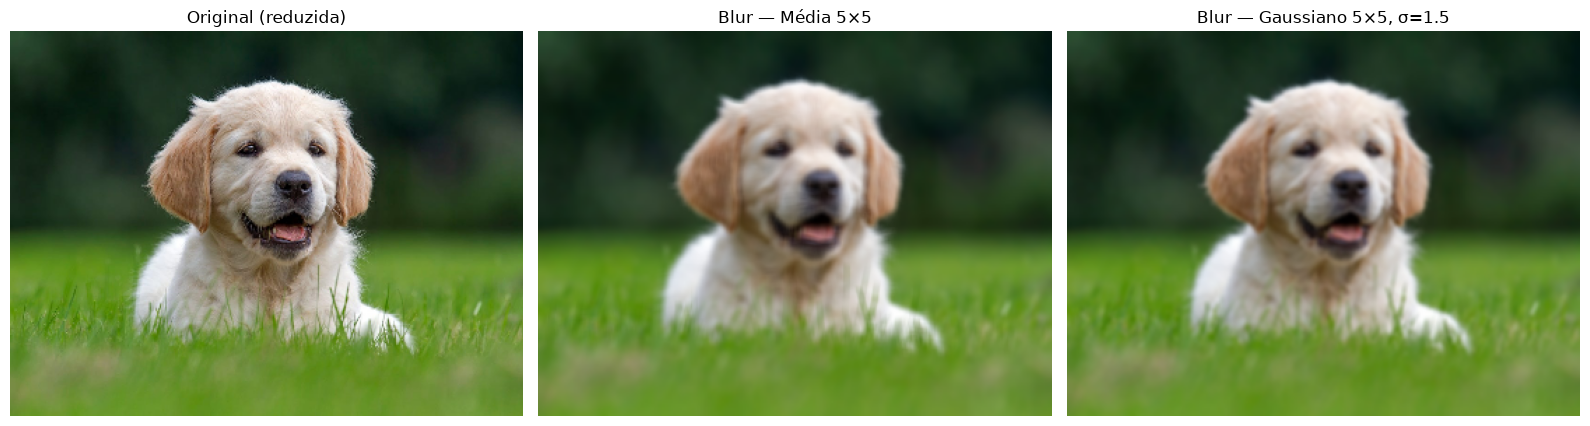

In [17]:
def kernel_media(tamanho=3):
    '''Kernel de média (box blur): pesos iguais, somando 1.'''
    return np.ones((tamanho, tamanho), dtype=np.float64) / (tamanho * tamanho)


def filtro_blur(imagem, tipo='gaussiano', tamanho=5, sigma=1.0):
    '''
    Usa a convolução vetorizada (Im2Col para média, separável para gaussiano)
    para que as demonstrações a seguir rodem rapidamente.
    '''
    if tipo == 'media':
        kernel = kernel_media(tamanho)
        saida = aplicar_convolucao_im2col(imagem, kernel)
    elif tipo == 'gaussiano':
        h_1d = kernel_gaussiano_1d(tamanho, sigma)
        saida = convolucao_separavel(imagem, h_1d)
    else:
        raise ValueError("tipo deve ser 'media' ou 'gaussiano'")
    return garantir_uint8(saida)


# Imagem de demonstração maior (menos decimada) para os filtros vetorizados
imagem_filtros = reduzir_imagem(imagem_original, 3)
print("Imagem original:", imagem_original.shape, " -> Imagem de demonstração:", imagem_filtros.shape)

blur_media = filtro_blur(imagem_filtros, tipo='media', tamanho=5)
blur_gauss = filtro_blur(imagem_filtros, tipo='gaussiano', tamanho=5, sigma=1.5)

fig, axs = plt.subplots(1, 3, figsize=(16, 6))
for ax, im, t in zip(axs, [imagem_filtros, blur_media, blur_gauss],
                      ['Original (reduzida)', 'Blur — Média 5×5', 'Blur — Gaussiano 5×5, σ=1.5']):
    ax.imshow(im)
    ax.set_title(t)
    ax.axis('off')
plt.tight_layout()
plt.show()

### 4.2 Sharpen (Realce de Nitidez)

A ideia do *sharpen* é **exagerar as diferenças locais** entre um pixel e
seus vizinhos, realçando bordas e texturas finas. Construímos esse kernel
somando a imagem original a uma versão amplificada do seu **Laplaciano**
(aproximação da segunda derivada, que detecta mudança rápida de intensidade):

$$
K_{\text{laplaciano}} =
\begin{bmatrix} 0 & -1 & 0 \\ -1 & 4 & -1 \\ 0 & -1 & 0 \end{bmatrix}
\qquad\Longrightarrow\qquad
g = f + K_{\text{laplaciano}} * f
$$

Somando o kernel identidade (representando "$f$") ao Laplaciano:

$$
K_{\text{sharpen}} =
\begin{bmatrix} 0 & 0 & 0 \\ 0 & 1 & 0 \\ 0 & 0 & 0 \end{bmatrix}
+
\begin{bmatrix} 0 & -1 & 0 \\ -1 & 4 & -1 \\ 0 & -1 & 0 \end{bmatrix}
=
\begin{bmatrix} 0 & -1 & 0 \\ -1 & 5 & -1 \\ 0 & -1 & 0 \end{bmatrix}
$$

A soma dos pesos é $5 - 1 - 1 - 1 - 1 = 1$, preservando o brilho médio da
imagem — só a nitidez local é afetada. Note que **este kernel não é
separável** (não existe produto externo de dois vetores 1D que o reproduza) —
é exatamente esse tipo de caso que justifica manter a convolução 2D genérica
da Seção 3 como ferramenta de propósito geral.


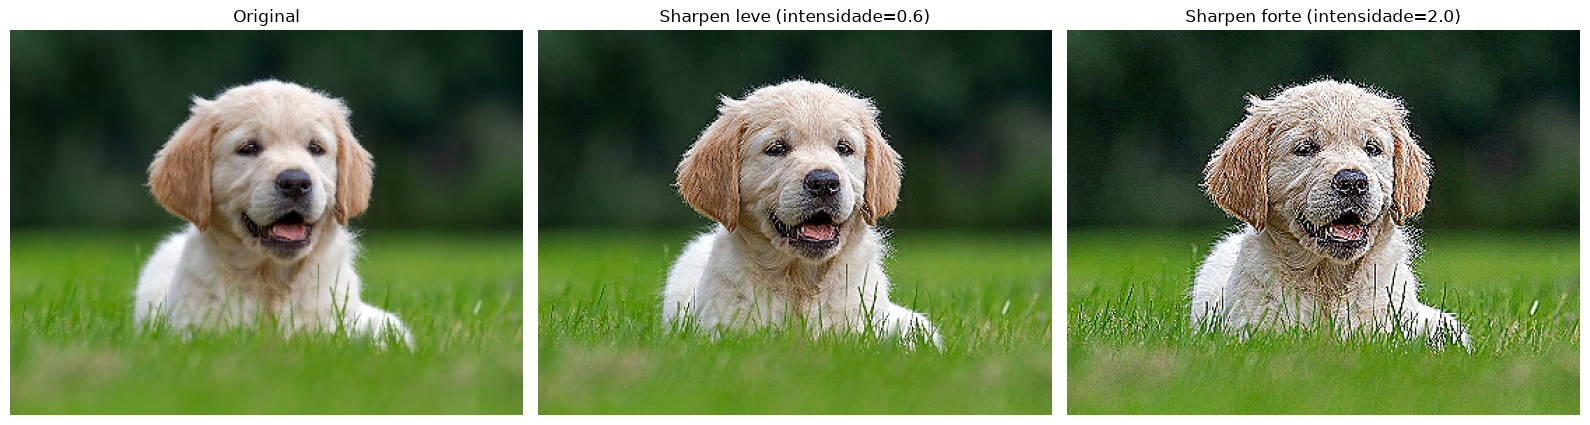

In [18]:
def kernel_sharpen(intensidade=1.0):
    '''
    Interpolação entre identidade e o kernel clássico de sharpen:
        kernel = identidade + intensidade * (kernel_classico - identidade)
    intensidade=0 -> identidade (sem efeito); intensidade=1 -> kernel clássico.
    '''
    identidade = np.array([[0, 0, 0], [0, 1, 0], [0, 0, 0]], dtype=np.float64)
    classico = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=np.float64)
    return identidade + intensidade * (classico - identidade)


def filtro_sharpen(imagem, intensidade=1.0):
    kernel = kernel_sharpen(intensidade)
    return garantir_uint8(aplicar_convolucao_im2col(imagem, kernel))


sharp_leve = filtro_sharpen(imagem_filtros, intensidade=0.6)
sharp_forte = filtro_sharpen(imagem_filtros, intensidade=2.0)

fig, axs = plt.subplots(1, 3, figsize=(16, 6))
for ax, im, t in zip(axs, [imagem_filtros, sharp_leve, sharp_forte],
                      ['Original', 'Sharpen leve (intensidade=0.6)', 'Sharpen forte (intensidade=2.0)']):
    ax.imshow(im)
    ax.set_title(t)
    ax.axis('off')
plt.tight_layout()
plt.show()

### 4.3 Sobel — Detecção de Bordas por Gradiente

O operador de **Sobel** aproxima as derivadas parciais $\partial f/\partial x$
e $\partial f/\partial y$ através de dois kernels $3\times3$:

$$
G_x =
\begin{bmatrix} -1 & 0 & 1 \\ -2 & 0 & 2 \\ -1 & 0 & 1 \end{bmatrix}
\qquad\qquad
G_y =
\begin{bmatrix} -1 & -2 & -1 \\ 0 & 0 & 0 \\ 1 & 2 & 1 \end{bmatrix}
$$

Cada kernel combina uma **derivada** ao longo de um eixo (coluna ou linha
$[-1, 0, 1]$) com uma **suavização** no eixo perpendicular (pesos
$[1, 2, 1]$) — por isso o Sobel é mais robusto a ruído que uma derivada
"crua" $[-1, 0, 1]$: já embute um pequeno blur perpendicular ao gradiente.
(Aliás, $G_x$ e $G_y$ **também são separáveis** — cada um é o produto externo
de um kernel de derivada 1D por um kernel de suavização 1D $[1,2,1]$; fica
como exercício aplicar a Seção 3.5 aqui.)

A partir de $G_x$ e $G_y$, calculamos a **magnitude do gradiente** (força da
borda) e sua **direção**:

$$ |\nabla f| = \sqrt{G_x^2 + G_y^2} \qquad\qquad \theta = \arctan\!\left(\frac{G_y}{G_x}\right) $$

> **Convolução vs. correlação, revisitado:** nossa `aplicar_convolucao` inverte
> o kernel em 180° antes de aplicá-lo. Para $G_x$ e $G_y$, que são
> **anti-simétricos**, essa inversão troca o sinal do resultado (gradiente na
> direção oposta). Como **elevamos ao quadrado** na fórmula da magnitude, o
> sinal desaparece — o mapa de bordas final é **idêntico**, com convolução ou
> correlação. Já a **direção** $\theta$ *seria* afetada por essa troca de
> sinal (mudaria $180°$) — algo a se ter em mente antes do NMS na Seção 5.


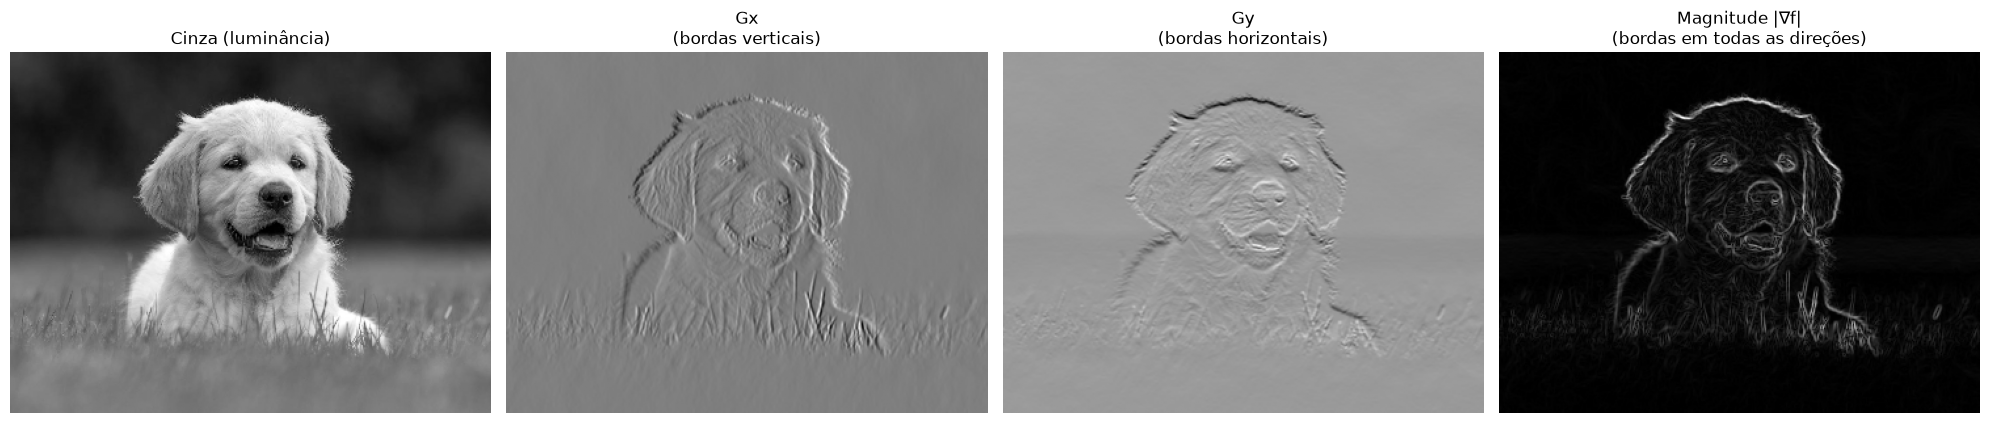

In [19]:
KERNEL_SOBEL_X = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1],
], dtype=np.float64)

KERNEL_SOBEL_Y = np.array([
    [-1, -2, -1],
    [0, 0, 0],
    [1, 2, 1],
], dtype=np.float64)


def converter_para_cinza(imagem):
    '''
    Luminância perceptual (ITU-R BT.601): Y = 0.299R + 0.587G + 0.114B.
    Retorna float64 (sem converter para uint8) para preservar precisão
    numérica nos próximos passos do pipeline (blur, contraste, Sobel...).
    '''
    img = imagem.astype(np.float64)
    R, G, B = img[..., 0], img[..., 1], img[..., 2]
    return 0.299 * R + 0.587 * G + 0.114 * B


def filtro_sobel(imagem_cinza):
    '''
    Aplica Gx e Gy sobre uma imagem em tons de cinza (HxW) e retorna
    Gx, Gy, magnitude |∇f| = sqrt(Gx²+Gy²) e direção θ = atan2(Gy, Gx) em radianos.
    Usamos atan2 (não atan(Gy/Gx)) para evitar divisão por zero e obter o
    ângulo completo no intervalo (-π, π].
    '''
    gx = aplicar_convolucao_im2col(imagem_cinza, KERNEL_SOBEL_X)
    gy = aplicar_convolucao_im2col(imagem_cinza, KERNEL_SOBEL_Y)
    magnitude = np.sqrt(gx**2 + gy**2)
    direcao = np.arctan2(gy, gx)
    return gx, gy, magnitude, direcao


cinza_demo = converter_para_cinza(imagem_filtros)
gx_demo, gy_demo, mag_demo, dir_demo = filtro_sobel(cinza_demo)

fig, axs = plt.subplots(1, 4, figsize=(20, 5))
imagens = [cinza_demo, gx_demo, gy_demo, mag_demo]
titulos = ['Cinza (luminância)', 'Gx\n(bordas verticais)', 'Gy\n(bordas horizontais)',
           'Magnitude |∇f|\n(bordas em todas as direções)']
for ax, im, t in zip(axs, imagens, titulos):
    ax.imshow(im, cmap='gray')
    ax.set_title(t)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 5. Do Gradiente ao Mapa Binário de Bordas: NMS e Otsu

A magnitude do Sobel produz bordas **grossas** (várias linhas de pixels com
gradiente alto ao redor de cada contorno real) e é **contínua** (valores em
$[0, \max|\nabla f|]$, não uma decisão binária "é borda / não é borda"). As
duas próximas técnicas resolvem exatamente isso — e são, não por acaso, os
passos 3 e 4 do algoritmo de **Canny**.

### 5.1 Supressão de Não-Máximos (Non-Maximum Suppression)

**Ideia:** um pixel só deve sobreviver como "borda" se sua magnitude for um
**máximo local ao longo da direção do gradiente** — ou seja, maior que os
dois vizinhos imediatamente "antes" e "depois" dele nessa direção. Isso afina
bordas grossas para ~1 pixel de espessura.

**Passo 1 — Quantizar a direção:** $\theta$ é contínuo, mas só precisamos
saber a qual dos **4 setores** (0°, 45°, 90°, 135°, e seus equivalentes por
simetria de 180°) o gradiente mais se aproxima, pois cada setor tem apenas 2
vizinhos discretos na grade de pixels:

| Setor | Ângulo de $\theta$ (mod 180°) | Vizinhos comparados |
|---|---|---|
| Horizontal | $[0°, 22.5°) \cup [157.5°, 180°)$ | esquerda, direita |
| Diagonal ↗ | $[22.5°, 67.5°)$ | inferior-esquerda, superior-direita |
| Vertical | $[67.5°, 112.5°)$ | acima, abaixo |
| Diagonal ↘ | $[112.5°, 157.5°)$ | superior-esquerda, inferior-direita |

**Passo 2 — Suprimir:** se $|\nabla f|(y,x)$ não for $\geq$ que **ambos** os
vizinhos do setor correspondente, zeramos o pixel.


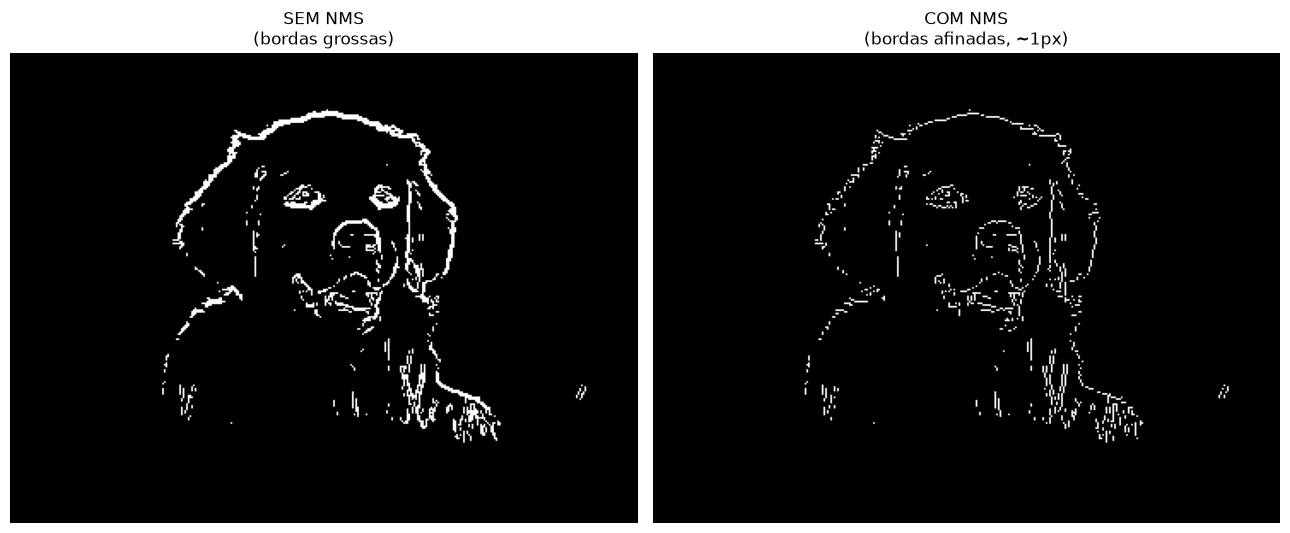

In [20]:
def supressao_nao_maximos(magnitude, direcao):
    '''
    Afina as bordas do Sobel para ~1 pixel, mantendo apenas máximos locais ao
    longo da direção do gradiente (quantizada em 4 setores de 45°).
    '''
    angulo_graus = np.degrees(direcao) % 180  # simetria: gradiente e seu oposto (+-180°) apontam para a mesma reta
    mag_pad = np.pad(magnitude, 1, mode='constant')  # borda vira 0: nunca vence a supressão

    centro = mag_pad[1:-1, 1:-1]
    esquerda, direita = mag_pad[1:-1, 0:-2], mag_pad[1:-1, 2:]
    cima, baixo = mag_pad[0:-2, 1:-1], mag_pad[2:, 1:-1]
    sup_esq, sup_dir = mag_pad[0:-2, 0:-2], mag_pad[0:-2, 2:]
    inf_esq, inf_dir = mag_pad[2:, 0:-2], mag_pad[2:, 2:]

    mask_h = (angulo_graus < 22.5) | (angulo_graus >= 157.5)
    mask_d1 = (angulo_graus >= 22.5) & (angulo_graus < 67.5)
    mask_v = (angulo_graus >= 67.5) & (angulo_graus < 112.5)
    mask_d2 = (angulo_graus >= 112.5) & (angulo_graus < 157.5)

    e_maximo = np.zeros_like(magnitude, dtype=bool)
    e_maximo[mask_h] = (centro[mask_h] >= esquerda[mask_h]) & (centro[mask_h] >= direita[mask_h])
    e_maximo[mask_d1] = (centro[mask_d1] >= sup_dir[mask_d1]) & (centro[mask_d1] >= inf_esq[mask_d1])
    e_maximo[mask_v] = (centro[mask_v] >= cima[mask_v]) & (centro[mask_v] >= baixo[mask_v])
    e_maximo[mask_d2] = (centro[mask_d2] >= sup_esq[mask_d2]) & (centro[mask_d2] >= inf_dir[mask_d2])

    resultado = np.zeros_like(magnitude)
    resultado[e_maximo] = magnitude[e_maximo]
    return resultado


mag_nms = supressao_nao_maximos(mag_demo, dir_demo)
limiar_visual = mag_demo.max() * 0.25

fig, axs = plt.subplots(1, 2, figsize=(13, 6))
axs[0].imshow(mag_demo > limiar_visual, cmap='gray')
axs[0].set_title('SEM NMS\n(bordas grossas)')
axs[1].imshow(mag_nms > limiar_visual, cmap='gray')
axs[1].set_title('COM NMS\n(bordas afinadas, ~1px)')
for ax in axs:
    ax.axis('off')
plt.tight_layout()
plt.show()

### 5.2 Binarização: Limiar Manual vs. Método de Otsu

Um **limiar manual** ($g > t \Rightarrow$ borda) funciona, mas $t$ precisa ser
"chutado" e recalibrado para cada imagem/iluminação. O **método de Otsu**
(1979) calcula $t$ **automaticamente**, assumindo que o histograma de
intensidades é (aproximadamente) **bimodal**: um agrupamento de pixels
"fundo" e outro de pixels "borda/objeto".

**Formulação:** para um limiar candidato $t \in \{0, ..., 255\}$, divida os
pixels em duas classes, $C_0 = \{f \le t\}$ e $C_1 = \{f > t\}$. Sejam
$w_0(t), w_1(t)$ as proporções de pixels em cada classe e
$\mu_0(t), \mu_1(t)$ suas médias. A **variância entre classes** é:

$$ \sigma_B^2(t) = w_0(t)\, w_1(t)\, \big[\mu_0(t) - \mu_1(t)\big]^2 $$

O limiar ótimo de Otsu é o que **maximiza** $\sigma_B^2(t)$:

$$ t^\star = \arg\max_{t} \ \sigma_B^2(t) $$

Intuição: quanto mais separadas (e mais "puras" em população) as duas
classes, maior $\sigma_B^2$. Isso é equivalente a **minimizar a variância
intra-classe** $\sigma_W^2(t) = w_0(t)\sigma_0^2(t) + w_1(t)\sigma_1^2(t)$,
pois $\sigma_B^2(t) + \sigma_W^2(t) = \sigma_{\text{total}}^2$ (constante,
independente de $t$) — uma identidade clássica de decomposição de variância.

**Implementação eficiente:** em vez de recalcular médias e variâncias do zero
para cada um dos 256 limiares candidatos, usamos **somas cumulativas** do
histograma $h(k)$, $k=0,\dots,255$:

$$ w_0(t) = \sum_{k=0}^{t} \frac{h(k)}{N} \qquad\qquad \mu_0(t) = \frac{\sum_{k=0}^{t} k\, h(k)}{\sum_{k=0}^{t} h(k)} $$

e analogamente para $w_1, \mu_1$ com $k > t$. A busca por $t^\star$ ainda
percorre os 256 níveis, mas sem laço sobre os pixels da imagem.


In [21]:
def limiar_otsu(imagem):
    '''
    Calcula o limiar de Otsu (maximiza a variância entre classes) via
    somas cumulativas do histograma — sem laço sobre pixels.
    '''
    imagem_uint8 = imagem if imagem.dtype == np.uint8 else garantir_uint8(imagem)
    histograma, _ = np.histogram(imagem_uint8, bins=256, range=(0, 256))
    total_pixels = imagem_uint8.size
    niveis = np.arange(256)

    peso_acumulado = np.cumsum(histograma).astype(np.float64)          # w0(t) * total, para cada t
    soma_acumulada = np.cumsum(niveis * histograma).astype(np.float64)  # numerador de mu0(t)
    soma_total = soma_acumulada[-1]

    w0 = peso_acumulado / total_pixels
    w1 = 1.0 - w0

    with np.errstate(divide='ignore', invalid='ignore'):
        mu0 = np.where(peso_acumulado > 0, soma_acumulada / peso_acumulado, 0.0)
        peso_resto = total_pixels - peso_acumulado
        mu1 = np.where(peso_resto > 0, (soma_total - soma_acumulada) / peso_resto, 0.0)

    variancia_entre_classes = np.nan_to_num(w0 * w1 * (mu0 - mu1) ** 2)
    return int(np.argmax(variancia_entre_classes))


# Sanity check em imagem sintética bimodal: dois "aglomerados" gaussianos de
# intensidade, centrados em 60 e 190. O limiar de Otsu deve cair ENTRE as duas médias.
rng = np.random.default_rng(42)
fundo = rng.normal(loc=60, scale=15, size=(100, 100))
objeto = rng.normal(loc=190, scale=15, size=(100, 100))
imagem_bimodal = garantir_uint8(np.where(np.indices((100, 100))[1] < 50, fundo, objeto))

t_otsu_teste = limiar_otsu(imagem_bimodal)
print("Limiar de Otsu encontrado:", t_otsu_teste, "(esperado entre 60 e 190)")
assert 60 < t_otsu_teste < 190, "Limiar de Otsu fora do vale esperado entre os dois clusters"

Limiar de Otsu encontrado: 111 (esperado entre 60 e 190)


Limiar manual (chutado): 50
Limiar de Otsu (automático): 38


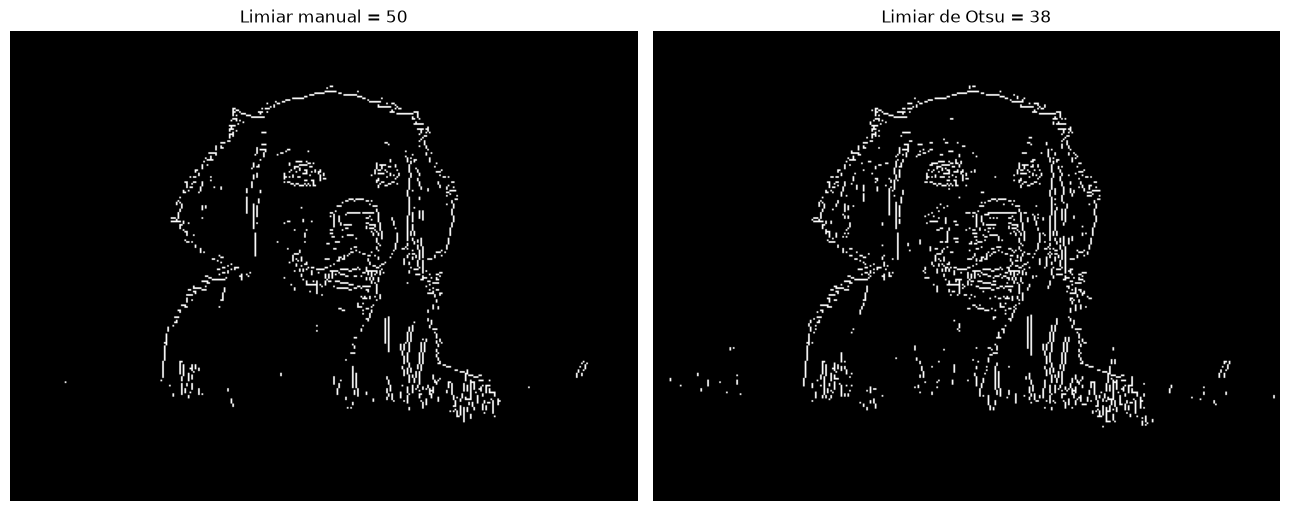

In [22]:
# Comparando limiar manual "chutado" vs. Otsu automático, no mapa de magnitude pós-NMS
mag_norm = garantir_uint8((mag_nms / mag_nms.max()) * 255.0)

limiar_manual = 50
t_otsu = limiar_otsu(mag_norm)
print("Limiar manual (chutado):", limiar_manual)
print("Limiar de Otsu (automático):", t_otsu)

bordas_manual = (mag_norm > limiar_manual).astype(np.uint8) * 255
bordas_otsu = (mag_norm > t_otsu).astype(np.uint8) * 255

fig, axs = plt.subplots(1, 2, figsize=(13, 6))
axs[0].imshow(bordas_manual, cmap='gray')
axs[0].set_title(f'Limiar manual = {limiar_manual}')
axs[1].imshow(bordas_otsu, cmap='gray')
axs[1].set_title(f'Limiar de Otsu = {t_otsu}')
for ax in axs:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 6. Pipeline Completo de Detecção de Bordas (um "quase-Canny")

A ordem das operações não é arbitrária — cada etapa resolve um problema
criado (ou revelado) pela etapa anterior.

**Por que tons de cinza primeiro?** O Sobel mede gradientes de intensidade;
não há necessidade de gradientes separados por canal quando o que interessa
são os contornos estruturais. Reduz também o volume de dados em 3×.

**Por que blur antes do Sobel?** A derivada é extremamente sensível a ruído:
pequenas flutuações (ruído do sensor, textura fina, compressão JPEG) geram
gradientes altos que o Sobel confundiria com "bordas falsas". Suavizar
**antes** de derivar elimina essas variações de alta frequência, preservando
as transições estruturalmente significativas — a mesma lógica do primeiro
passo do algoritmo de Canny: *suavizar, depois derivar*.

**Por que (opcionalmente) ajustar o contraste?** Transições sutis produzem
gradientes fracos, dificultando a separação borda/não-borda mesmo com Otsu.
Aplicamos o ajuste **depois** do blur (para não amplificar ruído ainda não
suavizado) e **antes** do Sobel (para que o gradiente "enxergue" transições
mais nítidas).

**Pipeline completo:**

1. Carregar e (por performance) reduzir a imagem
2. Tons de cinza (luminância BT.601)
3. Blur Gaussiano separável (redução de ruído)
4. Ajuste de contraste (opcional)
5. Sobel: $G_x$, $G_y$, magnitude, direção
6. Supressão de Não-Máximos (afina as bordas)
7. Binarização automática via Otsu


In [23]:
def pipeline_deteccao_bordas(imagem, fator_reducao=3, sigma_blur=1.4, alpha_contraste=1.3):
    '''Executa o pipeline completo e retorna um dicionário com todas as etapas intermediárias.'''
    imagem_reduzida = reduzir_imagem(imagem, fator_reducao)

    cinza = converter_para_cinza(imagem_reduzida)
    h_1d = kernel_gaussiano_1d(tamanho=5, sigma=sigma_blur)
    blur = convolucao_separavel(cinza, h_1d)
    contraste = ajustar_brilho_contraste(blur, alpha=alpha_contraste, beta=0).astype(np.float64)

    gx, gy, magnitude, direcao = filtro_sobel(contraste)
    mag_nms_pipeline = supressao_nao_maximos(magnitude, direcao)

    mag_norm_pipeline = garantir_uint8((mag_nms_pipeline / mag_nms_pipeline.max()) * 255.0)
    t_otsu_pipeline = limiar_otsu(mag_norm_pipeline)
    bordas_binarias = (mag_norm_pipeline > t_otsu_pipeline).astype(np.uint8) * 255

    return {
        'original': imagem_reduzida, 'cinza': cinza, 'blur': blur, 'contraste': contraste,
        'gx': gx, 'gy': gy, 'magnitude': magnitude, 'nms': mag_nms_pipeline,
        'limiar_otsu': t_otsu_pipeline, 'bordas': bordas_binarias,
    }

imagem_bordas = plt.imread('imgs/edge_warp.jpeg')
resultado = pipeline_deteccao_bordas(imagem_bordas)
print("Pipeline concluído. Limiar de Otsu escolhido automaticamente:", resultado['limiar_otsu'])
print("Shape do resultado final:", resultado['bordas'].shape)

Pipeline concluído. Limiar de Otsu escolhido automaticamente: 97
Shape do resultado final: (510, 510)


### 6.1 Visualizando o pipeline completo: Antes → Passos Intermediários → Resultado Final


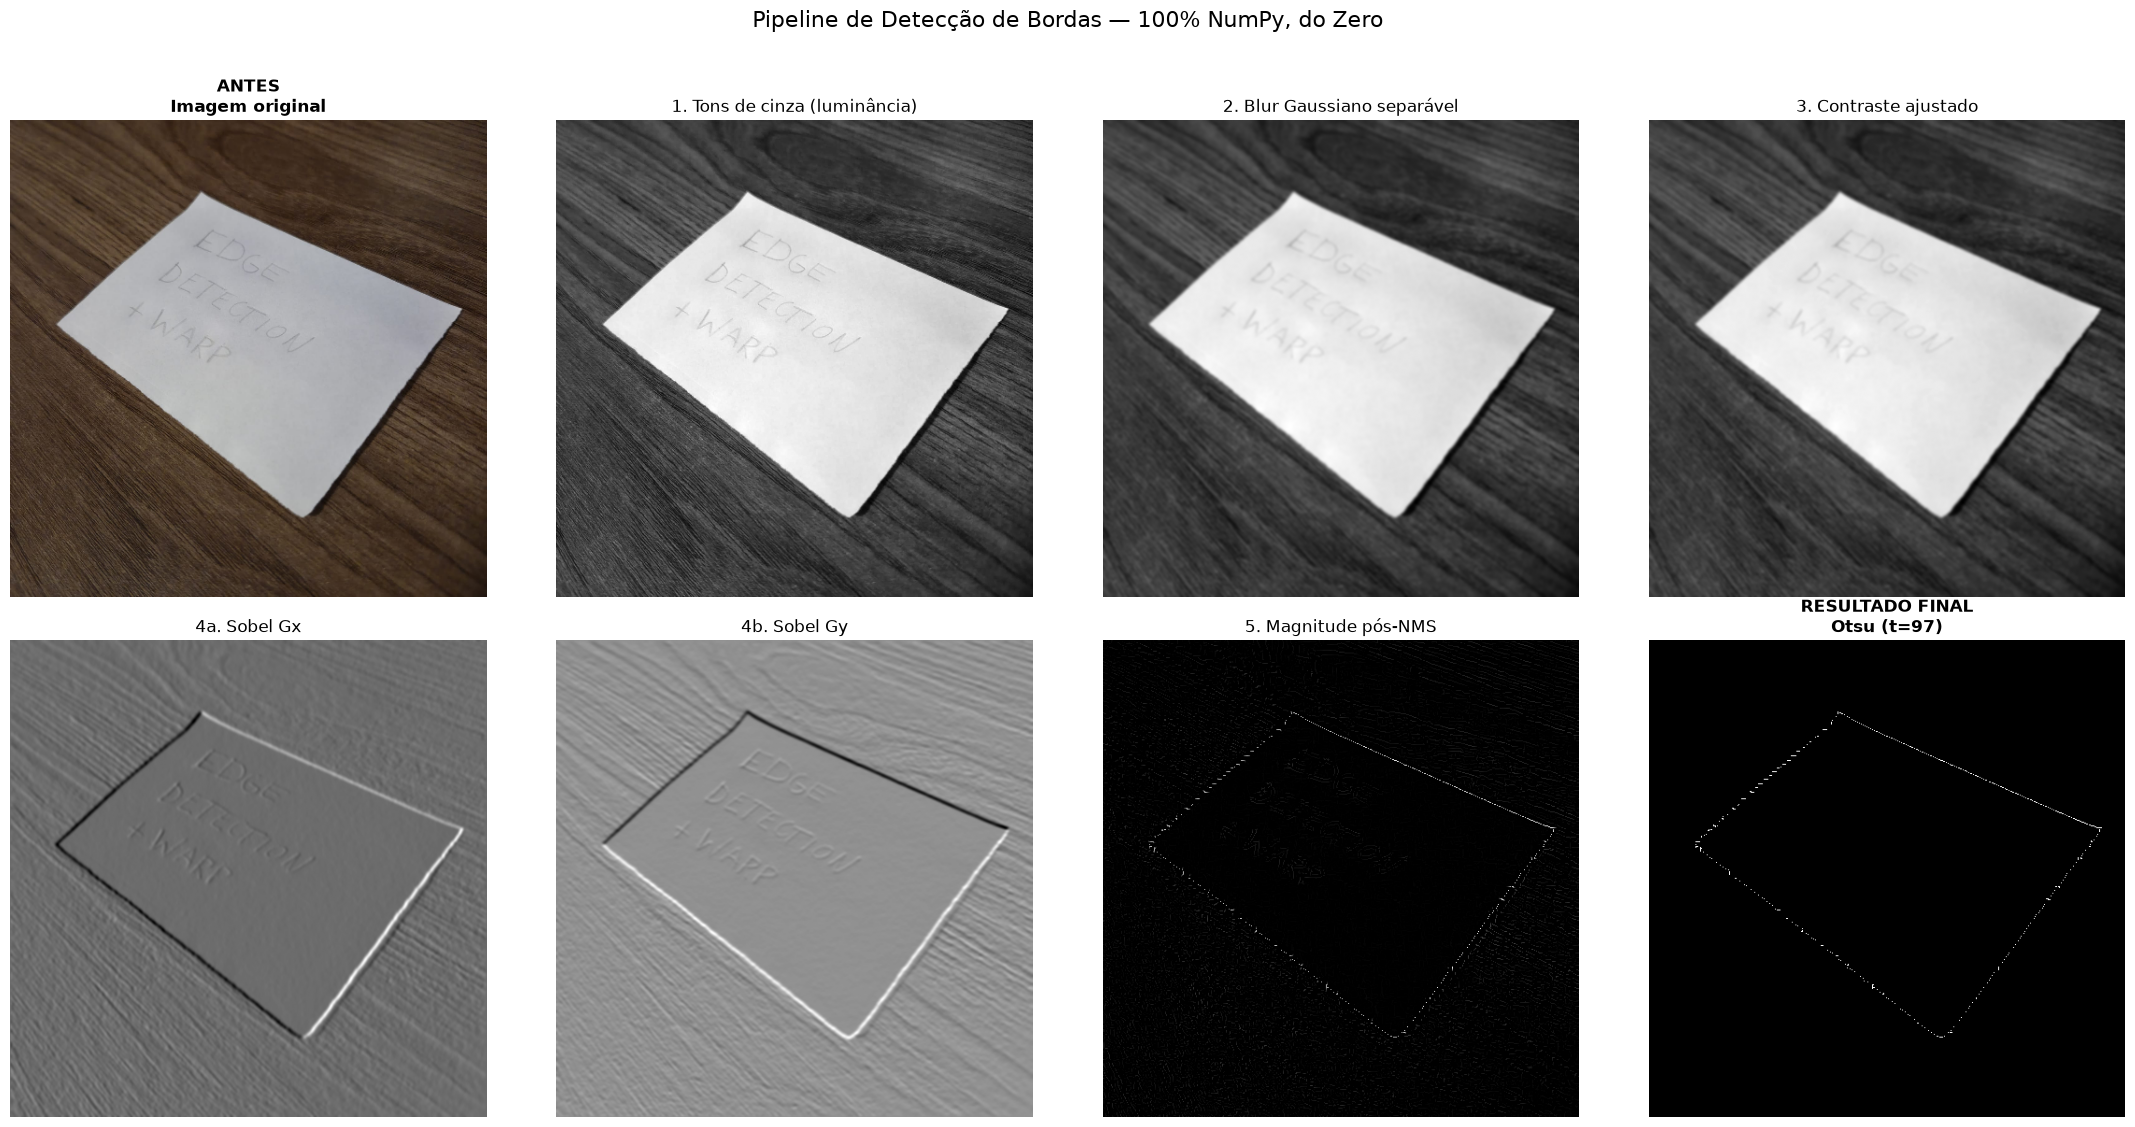

In [24]:
fig, axs = plt.subplots(2, 4, figsize=(22, 11))

axs[0, 0].imshow(resultado['original'])
axs[0, 0].set_title('ANTES\nImagem original', fontsize=12, fontweight='bold')
axs[0, 1].imshow(resultado['cinza'], cmap='gray')
axs[0, 1].set_title('1. Tons de cinza (luminância)')
axs[0, 2].imshow(resultado['blur'], cmap='gray')
axs[0, 2].set_title('2. Blur Gaussiano separável')
axs[0, 3].imshow(resultado['contraste'], cmap='gray')
axs[0, 3].set_title('3. Contraste ajustado')

axs[1, 0].imshow(resultado['gx'], cmap='gray')
axs[1, 0].set_title('4a. Sobel Gx')
axs[1, 1].imshow(resultado['gy'], cmap='gray')
axs[1, 1].set_title('4b. Sobel Gy')
axs[1, 2].imshow(resultado['nms'], cmap='gray')
axs[1, 2].set_title('5. Magnitude pós-NMS')
axs[1, 3].imshow(resultado['bordas'], cmap='gray')
axs[1, 3].set_title(f"RESULTADO FINAL\nOtsu (t={resultado['limiar_otsu']})", fontweight='bold')

for ax in axs.ravel():
    ax.axis('off')

plt.suptitle('Pipeline de Detecção de Bordas — 100% NumPy, do Zero', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

### 6.2 Prova visual: por que o blur antes do Sobel realmente importa

Rodamos o mesmo pipeline **sem** o passo de blur, comparando lado a lado.
Preste atenção à textura fina do fundo — sem blur, o Sobel confunde
detalhes de alta frequência com bordas verdadeiras.


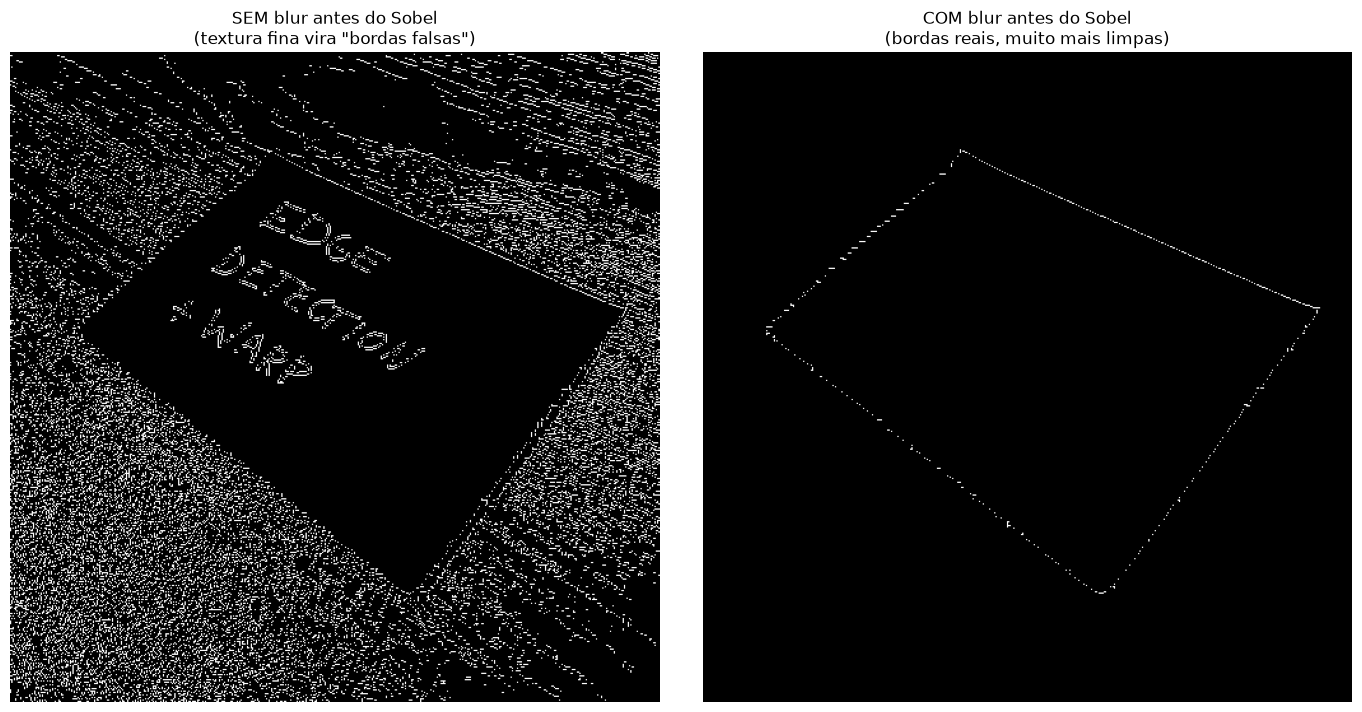

In [97]:
# Pipeline "ingênuo": Sobel + NMS + Otsu direto no cinza, sem blur antes
gx_sb, gy_sb, mag_sb, dir_sb = filtro_sobel(resultado['cinza'])
mag_sb_nms = supressao_nao_maximos(mag_sb, dir_sb)
mag_sb_norm = garantir_uint8((mag_sb_nms / mag_sb_nms.max()) * 255.0)
bordas_sem_blur = (mag_sb_norm > limiar_otsu(mag_sb_norm)).astype(np.uint8) * 255

fig, axs = plt.subplots(1, 2, figsize=(14, 7))
axs[0].imshow(bordas_sem_blur, cmap='gray')
axs[0].set_title('SEM blur antes do Sobel\n(textura fina vira "bordas falsas")')
axs[1].imshow(resultado['bordas'], cmap='gray')
axs[1].set_title('COM blur antes do Sobel\n(bordas reais, muito mais limpas)')
for ax in axs:
    ax.axis('off')
plt.tight_layout()
plt.show()

### 6.3 Do mapa de bordas às quinas do objeto (ponte para a Aula 3)

O mapa binário de bordas nos diz *onde* estão as transições, mas a Aula 3
(retificação de perspectiva) precisa de algo mais compacto: as **quatro
quinas** do objeto fotografado. Um heurístico simples — que só funciona bem
para objetos **convexos**, como uma folha de papel — é pegar os pixels de
borda mais extremos em cada direção do plano (mais alto, mais à direita, mais
baixo, mais à esquerda). Para um quadrilátero convexo suficientemente
rotacionado, cada um desses extremos tende a coincidir com um canto real.

Vamos calcular essas quatro extremidades e salvar em
`fragments/extremidades_objeto.txt`. Esse arquivo será **carregado
diretamente** no início da Aula 3 — em vez de recalcularmos (ou pior,
chutarmos manualmente de novo) os mesmos quatro pontos.


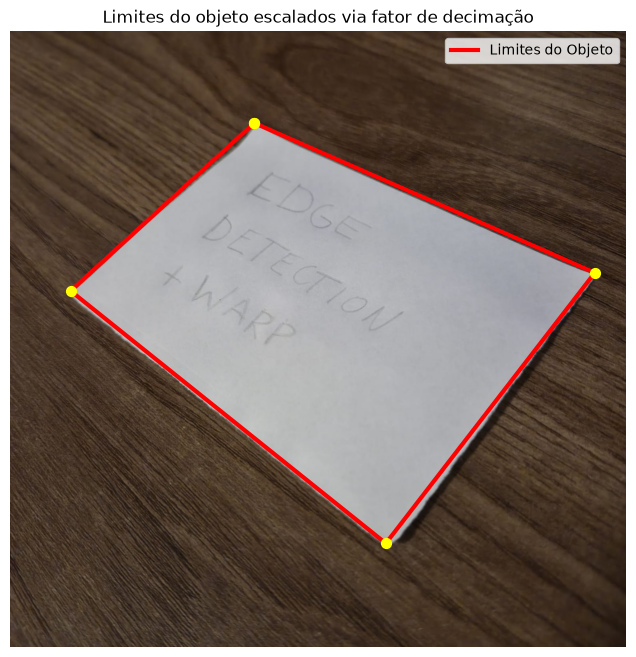

Coordenadas das extremidades do objeto (em pixels na imagem original):
Topo: (np.float64(605.2078431372549), np.float64(227.7019607843137))
Direita: (np.float64(1450.1019607843136), np.float64(599.2156862745098))
Base: (np.float64(931.7803921568627), np.float64(1270.3372549019607))
Esquerda: (np.float64(149.80392156862746), np.float64(644.156862745098))
Coordenadas das extremidades do objeto (lidas do arquivo):
[(np.float64(605.2078431372549), np.float64(227.7019607843137)), (np.float64(1450.1019607843136), np.float64(599.2156862745098)), (np.float64(931.7803921568627), np.float64(1270.3372549019607)), (np.float64(149.80392156862746), np.float64(644.156862745098))]


In [ ]:
# Mapa de bordas do pipeline (0 = fundo, 255 = borda)
mapa_bordas = resultado['bordas']

# Encontra as coordenadas (y, x) onde há borda
ys, xs = np.where(mapa_bordas == 255)

fator_reducao = imagem_bordas.shape[0] / resultado['original'].shape[0]  # fator de redução da imagem original para a reduzida

# 1. Encontrar os índices das 4 extremidades no mapa de bordas reduzido
idx_topo = np.argmin(ys)     # Ponto de menor Y (mais alto)
idx_base = np.argmax(ys)     # Ponto de maior Y (mais baixo)
idx_esq = np.argmin(xs)      # Ponto de menor X (mais à esquerda)
idx_dir = np.argmax(xs)      # Ponto de maior X (mais à direita)

# 2. Extrair os pontos (x, y) e já escalar para a imagem original
# Basta multiplicar as coordenadas pelo fator de redução!
p_topo = (xs[idx_topo] * fator_reducao, ys[idx_topo] * fator_reducao)
p_dir  = (xs[idx_dir] * fator_reducao,  ys[idx_dir] * fator_reducao)
p_base = (xs[idx_base] * fator_reducao, ys[idx_base] * fator_reducao)
p_esq  = (xs[idx_esq] * fator_reducao,  ys[idx_esq] * fator_reducao)

# Lista de pontos ordenados para formar o polígono 
# (o p_topo é repetido no final para "fechar" a linha perfeitamente)
pontos = [p_topo, p_dir, p_base, p_esq, p_topo]

# Separar Xs e Ys para o Matplotlib desenhar
x_linha = [p[0] for p in pontos]
y_linha = [p[1] for p in pontos]

# 3. Exibição
plt.figure(figsize=(8, 8))

# Exibe a imagem original de fundo (em alta resolução)
plt.imshow(imagem_bordas) 

# Traça a linha vermelha conectando as 4 extremidades
plt.plot(x_linha, y_linha, color='red', linewidth=3, label='Limites do Objeto')

# Marcadores amarelos apenas para destacar os 4 cantos exatos
plt.scatter(x_linha, y_linha, color='yellow', s=50, zorder=5) 

plt.title("Limites do objeto escalados via fator de decimação")
plt.axis("off")
plt.legend()
plt.show()

print("Coordenadas das extremidades do objeto (em pixels na imagem original):")
print(f"Topo: {p_topo}")
print(f"Direita: {p_dir}")
print(f"Base: {p_base}")
print(f"Esquerda: {p_esq}")

# Formato simples (uma linha "x y" por ponto) para a Aula 3 carregar com
# np.loadtxt, sem precisar reimplementar esta detecção.
quinas_objeto = np.array([p_topo, p_dir, p_base, p_esq], dtype=np.float64)
np.savetxt("fragments/extremidades_objeto.txt", quinas_objeto,
           header="x y -- ordem: topo, direita, base, esquerda")
print("\nSalvo em fragments/extremidades_objeto.txt para reutilização na Aula 3.")


## 🎓 Conclusão e Próximos Passos

Nesta aula construímos, **inteiramente do zero e usando apenas NumPy**, um
conjunto de ferramentas que forma a espinha dorsal de qualquer biblioteca de
Visão Computacional:

- Operações ponto a ponto: brilho/contraste, composição alfa, RGB ↔ HSV;
- Uma teoria e implementação completas de **convolução 2D** — definição
  formal, três estratégias de padding, versão ingênua (loops), vetorizada
  (Im2Col/GEMM), separável (Gaussiano) e via FFT (Teorema da Convolução);
- Os filtros clássicos **Blur**, **Sharpen** e **Sobel**;
- **Supressão de Não-Máximos** e **limiarização automática via Otsu**;
- Um **pipeline completo** de detecção de bordas, com justificativa
  matemática para cada etapa e um contrato de saída testado.

O último passo do pipeline (Seção 6.3) salvou as quatro extremidades do
objeto em `fragments/extremidades_objeto.txt`. **A Aula 3 começa carregando
exatamente esse arquivo** para transformar a fotografia em perspectiva em um
documento retificado — a detecção de bordas de hoje é o ponto de partida
geométrico de amanhã, não um exercício isolado.

### 🚀 Desafios propostos

**Suas próprias imagens:** troque `caminho_imagem` por uma foto sua e rode
   o pipeline completo. Teste diferentes valores de `sigma_blur` e observe o
   impacto no resultado final e no limiar de Otsu escolhido.

Bom trabalho, e até a próxima aula! 👋
